<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/HybridANN_VQC_IntrusionDetection_Venkatachalam2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid CNN-LSTM-DNN, QSVM and VQC for network intrusion detection: Venkatachalam and Liu (2023) step by step

This notebook re-implements, runs and checks the experiments of

> Praveen Venkatachalam and David Q. Liu, "On Hybrid Artificial Neural Networks and Variational Quantum Classifier for Network
> Intrusion Detection", *2023 International Conference on Cyber-Enabled Distributed Computing and Knowledge Discovery (CyberC)*,
> pp. 410-416, IEEE, 2023. DOI 10.1109/CyberC58899.2023.00070

The paper publishes no code and gives few settings (it is a seven-page conference paper). Everything below is written from its text
and figures; every place where the paper is silent is marked `# CHOICE:` in the code and listed in the table of Section "The paper in one page".

**What the notebook does.** It downloads the KDD Cup 1999 intrusion data (the dataset named in the paper), groups the 23 attack names into the
five classes of the paper (normal, DoS, Probe, R2L, U2R), and then trains the five models the paper compares:

1. a **hybrid artificial neural network** (one Conv1D layer, a max-pool, an LSTM layer, four dense layers and a 5-way softmax) on the
   42 features read as a time series of 42 steps with one value each;
2. a classical **SVM** with an RBF kernel and one with a polynomial kernel, on a few features produced by a dimensionality-reduction step
   (the paper tries PCA and kernel-PCA variants);
3. a **quantum-kernel SVM (QSVM)** with a ZZ feature map on the same few features;
4. a **variational quantum classifier (VQC)** with the same feature map and a trainable RealAmplitudes ansatz, trained with COBYLA.

A random forest and an RBF-SVM tuned on a validation split are added as extra classical baselines on exactly the same inputs as the quantum
models. The paper's figures (cost versus steps, VQC classification, QSVM metrics, HNN accuracy, AUC, mean absolute error and confusion
matrix) are redrawn from this run, and the last section puts every number the paper states next to ours with a verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned Qiskit
packages; if Colab asks to restart the session, restart and run all again. No GPU, no quantum-cloud account and no Kaggle login are needed:
the data is fetched by scikit-learn from a public mirror (fallback: the UCI archive).

**Runtime.** The committed notebook is the output of one complete run with `FAST_MODE = False` (4,051 records, 356 quantum training records, VQC with 300 COBYLA iterations
and 5 seeds, HNN with up to 15 epochs and 2 seeds), which took 64 minutes on a shared laptop CPU (the HNN alone took 43 of them). `FAST_MODE = True` (1,252 records, 100 quantum training records, 100 COBYLA iterations,
10 HNN epochs, one seed) takes about 10 minutes on the same machine; its HNN is under-trained on so few records and should not be compared with the paper.

**What you get at the end.** Accuracy, macro and weighted F1 of all models on the same test split, the HNN's multi-class AUC and mean
absolute error, the VQC cost curve, confusion matrices, the drawings of the circuits that were actually executed, and a table with one verdict per number in the paper.

## The paper in one page

**Problem.** Classify network connections into five classes (normal and four attack families) with classical and quantum models, and
show that quantum models could serve as stand-alone detectors in large classical data centres.

**Data.** "Real Kaggle datasets", features extracted from the **KDD Cup 99** data. The text never gives the number of records, the split or the class
balance. The five outputs of the HNN (Dense layer with 5 units) show that the five KDD families were used.

**Models and what the paper states.**

* **HNN** (Fig. 3): input = time series with 42 time steps and one feature; Conv1D (64 filters, size 3) -> MaxPooling1D (pool 2) -> LSTM
  (70 units, return sequences) -> Flatten -> four Dense layers of 1024, 768, 512, 256 units with ReLU and dropout (the text also says batch
  normalisation) -> Dense(5, softmax); categorical cross-entropy, Adam "with a specific learning rate". **Accuracy 79.4 %.**
* **SVM:** RBF kernel **accuracy 68 %, F1 68 %**; polynomial kernel **accuracy 75 %, F1 66 %** ("this shows the low dimensionality of the dataset").
* **QSVM:** quantum kernel $K(x,z)=|\langle\phi(x)|\phi(z)\rangle|^2$ (Eq. 11): **accuracy 64 %, F1 45 %**.
* **VQC:** state $U_w(\theta)U_f(x)|0\rangle$ (Eq. 12), cost = cross-entropy (Eq. 17): **accuracy 60 %** "with very minimal features".
* Dimensionality reduction by t-SNE, UMAP, PCA and kernel PCA (rbf, cosine, polynomial, sigmoid) is described as an "image transformer" step (Fig. 1: UMAP, Fig. 2: kPCA-RBF).
* Metrics: multi-class AUC (Eq. 13), accuracy (Eq. 14), categorical cross-entropy (Eq. 15), mean absolute error (Eq. 16). Figures 4-10 show the VQC cost, the VQC
  classification, the QSVM metrics, and for the HNN the accuracy curve, AUC, MAE and confusion matrix (no numbers are printed in the text for these).

The abstract summarises: classical ~80 % over all attack types, quantum 60 %.

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Data source | "real Kaggle datasets", KDD Cup 99 | KDD Cup 99 10 % file (494,021 records, 41 features + label) via `sklearn.datasets.fetch_kddcup99` (figshare mirror), fallback UCI archive; **not** the Kaggle copy, but the same file |
| Classes | 5 (Dense(5)) | normal, DoS, Probe, R2L, U2R by the standard KDD attack-family table |
| Duplicates | not mentioned | exact duplicate records removed (the 10 % file is 75 % duplicates, which would leak between train and test) |
| Class balance, sample size, split | not stated | class-balanced draw of up to `N_PER_CLASS` records per class (U2R has only 52), stratified 70 : 30 split, fixed seed |
| 42-step input of the HNN | 42 time steps, 1 feature | the 3 categorical columns are one-hot encoded, constant columns dropped, the 42 best columns by ANOVA F (`SelectKBest`, training split) are standardised and read as 42 steps |
| Feature reduction for SVM/QSVM/VQC | "very minimal features"; PCA/kPCA/UMAP/t-SNE shown | 4 components (one per qubit) from the reducer that does best on a validation split of the training data among PCA and four kernel-PCA variants; angles min-max scaled to [0, pi] on the training split |
| SVM kernels | RBF, polynomial; C, gamma, degree not given | RBF with scikit-learn defaults; polynomial $(1+x\cdot z)^3$ as in Eq. 10; an RBF-SVM with (C, gamma) tuned on a validation split is added |
| QSVM feature map | "quantum feature map", not named | Qiskit `zz_feature_map`, `reps = 2`, linear entanglement; angle bandwidth tuned on a validation split of the training data |
| VQC circuit | not given | same ZZ feature map + `real_amplitudes(reps = 3)`, 4 qubits; Qiskit `VQC` with measured bit-strings mapped to the 5 classes by the Qiskit default (`x mod 5`) |
| VQC optimiser, steps | Fig. 4 "steps vs cost"; number not given | COBYLA, budget in the configuration cell |
| Quantum training-set size | not given | a class-balanced subset of the training split (`N_TRAIN_Q` records), because the simulation cost grows with it; the test split is the full one |
| F1 averaging | not stated | weighted F1 is the number compared with the paper (the paper's 68 / 68 pair for accuracy / F1 suggests it); macro F1 is reported next to it |
| HNN training | Adam, "specific learning rate", dropout, batch norm | Adam 1e-3, dropout 0.3, batch normalisation after each dense layer, batch 64, early stopping on a validation split of the training data |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib and tensorflow.
# The pip line runs on Colab (or wherever the Qiskit packages are missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None or importlib.util.find_spec("qiskit_aer") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Qiskit packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit, qiskit-aer and qiskit-machine-learning already present; skipping pip install.")

qiskit, qiskit-aer and qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False            # True: class demo (a few hundred records, 1 seed). False: full budgets documented below.
SEED      = 42              # CHOICE: the paper gives no seed
IBM_TOKEN = ""              # not used: the paper simulated its circuits, so no real-hardware cell exists in this notebook

N_QUBITS   = 4              # CHOICE: "very minimal features": one reduced feature per qubit
N_SELECTED = 42             # the HNN input has 42 time steps (paper); CHOICE: the 42 best columns by ANOVA F on the training split
CLASSES    = ["normal", "DoS", "Probe", "R2L", "U2R"]
TEST_SIZE  = 0.30           # CHOICE: the paper gives no split; 70 : 30 stratified
VAL_FRACTION = 0.25         # inner validation split of the TRAINING rows: used for every choice (reducer, bandwidth, C, gamma)
DROP_DUPLICATES = True      # CHOICE: the 10 % KDD file is mostly exact duplicates; they would leak between train and test
REDUCER_CANDIDATES = ["pca", "kpca_rbf", "kpca_cosine", "kpca_poly", "kpca_sigmoid"]   # the reducers named in the paper (UMAP / t-SNE have no transform())

FM_REPS      = 2            # CHOICE: ZZ feature map repetitions
ENTANGLEMENT = "linear"     # CHOICE: nearest-neighbour ZZ pairs
ANSATZ_REPS  = 3            # CHOICE: RealAmplitudes repetitions (Qiskit default)
SCALE_GRID   = [0.1, 0.25, 0.5, 1.0]            # CHOICE: angle bandwidth candidates (angle = scale * minmax(feature) * pi)
QSVM_C_GRID  = [1.0, 10.0, 100.0]               # CHOICE
SVM_C_GRID   = [1.0, 10.0, 100.0]               # CHOICE (tuned classical RBF-SVM)
SVM_GAMMA_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0]
SHOTS   = 1024              # CHOICE: sampler shots for the VQC
USE_AER = True              # False: reference StatevectorSampler (slower)
HNN_LR, HNN_DROPOUT, HNN_BATCH, HNN_PATIENCE = 1e-3, 0.3, 32, 5   # CHOICE: the paper only says "a specific learning rate"
PLOT_EVERY = 25             # redraw the live VQC cost curve every this many objective evaluations

if FAST_MODE:               # about 10 minutes on a laptop CPU
    N_PER_CLASS = 300       # records per class (U2R: all 52)
    N_TRAIN_Q   = 100       # class-balanced training records for QSVM / VQC (20 per class)
    N_FIT_REDUCER = 800     # rows used to fit the kernel-PCA reducers
    N_SHOT_CHECK = 40       # test records sent through the real shot-based Qiskit VQC network as a check
    VQC_MAXITER = 100
    VQC_SEEDS   = [42]
    HNN_EPOCHS  = 10
    HNN_SEEDS   = [42]
else:                       # about 60-90 minutes on a laptop CPU (see the note in the first cell)
    N_PER_CLASS = 1000
    N_TRAIN_Q   = 400
    N_FIT_REDUCER = 1500
    N_SHOT_CHECK = 100
    VQC_MAXITER = 300
    VQC_SEEDS   = [42, 43, 44, 45, 46]
    HNN_EPOCHS  = 15
    HNN_SEEDS   = [42, 43]

DATA_DIR    = "data"        # downloaded files are cached here
DATA_SOURCE = "auto"        # "auto": scikit-learn mirror, then UCI. Or the path of a local kddcup.data_10_percent[.gz] file

In [3]:
import os, time, warnings, gzip, io
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("TF_ENABLE_ONEDNN_OPTS", "0")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_auc_score, roc_curve)

import tensorflow as tf
tf.config.threading.set_intra_op_parallelism_threads(1)     # one thread: reproducible and friendly to shared machines
tf.config.threading.set_inter_op_parallelism_threads(1)
import keras
from keras import layers

import qiskit, qiskit_machine_learning
from qiskit.circuit.library import zz_feature_map, real_amplitudes
from qiskit.quantum_info import Statevector, Operator
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.algorithms import VQC, QSVC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.utils.loss_functions import CrossEntropyLoss
try:
    from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
    import qiskit_aer
except Exception:
    AerSamplerV2, USE_AER = None, False

algorithm_globals.random_seed = SEED
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| tensorflow", tf.__version__, "| keras", keras.__version__)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-aer", qiskit_aer.__version__ if AerSamplerV2 else "not used")
print(f"FAST_MODE = {FAST_MODE} | records per class {N_PER_CLASS} | quantum training records {N_TRAIN_Q} | VQC {VQC_MAXITER} COBYLA iterations x seeds {VQC_SEEDS} | HNN {HNN_EPOCHS} epochs x seeds {HNN_SEEDS}")

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | tensorflow 2.21.0 | keras 3.15.1
qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
FAST_MODE = False | records per class 1000 | quantum training records 400 | VQC 300 COBYLA iterations x seeds [42, 43, 44, 45, 46] | HNN 15 epochs x seeds [42, 43]


## 1. The KDD Cup 99 data

KDD Cup 99 (the DARPA/MIT Lincoln Lab 1998 evaluation, processed for the 1999 data-mining contest) describes each network connection by
41 features: 3 categorical ones (`protocol_type`, `service`, `flag`), basic connection counters (`duration`, `src_bytes`, ...), content features
(failed logins, root shells, ...) and time-window traffic statistics (`count`, `serror_rate`, ...). The label names the attack
(23 names in the 10 % file) or `normal`. The standard table groups the attacks into **DoS** (denial of service), **Probe** (scanning),
**R2L** (remote-to-local) and **U2R** (user-to-root), which are the four attack families and, with `normal`, the five outputs of the paper's network.

The paper used the Kaggle copy; this notebook loads the original 10 % file through scikit-learn (it is cached in `DATA_DIR`) and falls back to the UCI archive.
Records that are exact copies of each other (same 41 features and label) are removed, because the 10 % file contains hundreds of thousands of
repeated `smurf` and `neptune` records and a copy of a training record in the test split would inflate every score.

In [4]:
KDD_COLUMNS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent",
               "hot", "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root",
               "num_file_creations", "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login",
               "count", "srv_count", "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate",
               "diff_srv_rate", "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate",
               "dst_host_diff_srv_rate", "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate",
               "dst_host_srv_serror_rate", "dst_host_rerror_rate", "dst_host_srv_rerror_rate"]
CAT_COLS = ["protocol_type", "service", "flag"]
UCI_URL = "https://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz"

ATTACK_FAMILY = {"normal": "normal"}
for a in ["back", "land", "neptune", "pod", "smurf", "teardrop"]:
    ATTACK_FAMILY[a] = "DoS"
for a in ["satan", "ipsweep", "nmap", "portsweep"]:
    ATTACK_FAMILY[a] = "Probe"
for a in ["guess_passwd", "ftp_write", "imap", "phf", "multihop", "warezmaster", "warezclient", "spy"]:
    ATTACK_FAMILY[a] = "R2L"
for a in ["buffer_overflow", "loadmodule", "rootkit", "perl"]:
    ATTACK_FAMILY[a] = "U2R"

def load_kdd():
    """Return a DataFrame with the 41 KDD features and a 'label' column (attack name without the final dot)."""
    if DATA_SOURCE != "auto":
        raw = pd.read_csv(DATA_SOURCE, header=None, names=KDD_COLUMNS + ["label"])
        src = DATA_SOURCE
    else:
        try:
            from sklearn.datasets import fetch_kddcup99
            frame = fetch_kddcup99(percent10=True, as_frame=True, data_home=DATA_DIR, download_if_missing=True).frame
            assert frame.shape[1] == 42
            raw = frame.copy(); raw.columns = KDD_COLUMNS + ["label"]
            src = "scikit-learn fetch_kddcup99 (figshare mirror)"
        except Exception as e:
            print("scikit-learn mirror failed (%s); trying the UCI archive" % type(e).__name__)
            import requests
            path = os.path.join(DATA_DIR, "kddcup.data_10_percent.gz")
            if not os.path.exists(path):
                r = requests.get(UCI_URL, timeout=300); r.raise_for_status(); open(path, "wb").write(r.content)
            raw = pd.read_csv(path, header=None, names=KDD_COLUMNS + ["label"]); src = "UCI archive"
    for c in raw.columns:                                  # sklearn returns bytes in object columns
        if raw[c].dtype == object:
            raw[c] = raw[c].map(lambda v: v.decode() if isinstance(v, bytes) else v)
    for c in KDD_COLUMNS:
        if c not in CAT_COLS:
            raw[c] = pd.to_numeric(raw[c])
    raw["label"] = raw["label"].astype(str).str.rstrip(".")
    return raw, src

t0 = time.time()
kdd, source = load_kdd()
n_raw = len(kdd)
kdd["family"] = kdd["label"].map(ATTACK_FAMILY)
assert kdd["family"].notna().all(), "unmapped attack names: %s" % sorted(set(kdd.loc[kdd["family"].isna(), "label"]))
fam_before = kdd["family"].value_counts()
if DROP_DUPLICATES:
    kdd = kdd.drop_duplicates().reset_index(drop=True)
fam_after = kdd["family"].value_counts()
print(f"loaded in {time.time()-t0:.1f} s from {source}: {n_raw:,} records; after removing exact duplicates: {len(kdd):,}")
print("missing values:", int(kdd[KDD_COLUMNS].isna().sum().sum()), "| infinities:", int(np.isinf(kdd[KDD_COLUMNS].select_dtypes('number')).sum().sum()))
display(pd.DataFrame({"records (as downloaded)": fam_before, "records (after dedup)": fam_after}).loc[CLASSES])
kdd.head(3)

loaded in 287.7 s from scikit-learn fetch_kddcup99 (figshare mirror): 494,021 records; after removing exact duplicates: 145,586


missing values: 0 | infinities: 0


,records (as downloaded),records (after dedup)
family,,
normal,97278,87832
DoS,391458,54572
Probe,4107,2131
R2L,1126,999
U2R,52,52


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,...,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,family
0,0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,...,1.0,0.0,0.0,9,9,1.0,0.0,0.11,0.0,0.0,0.0,0.0,0.0,normal,normal
1,0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,...,1.0,0.0,0.0,19,19,1.0,0.0,0.05,0.0,0.0,0.0,0.0,0.0,normal,normal
2,0,tcp,http,SF,235,1337,0,0,0,0,0,1,0,0,0,...,1.0,0.0,0.0,29,29,1.0,0.0,0.03,0.0,0.0,0.0,0.0,0.0,normal,normal


## 2. Class-balanced sample, 70 : 30 split and the preprocessing pipeline

The paper does not give the number of records, the class balance or the split. KDD's natural class balance is 80 % DoS, 20 % normal and
a handful of everything else, which makes accuracy a poor yardstick. We therefore draw up to `N_PER_CLASS` records per class at random
(`random_state = SEED`; the rare classes contribute everything they have) and split 70 : 30 with stratification. **Every fitted transform below sees the training part only.**

* one-hot encoding of `protocol_type`, `service`, `flag` (the categories come from the training split; a category that only occurs in the test split becomes all zeros), constant columns dropped;
* `SelectKBest(f_classif, k=42)`: the 42 columns that best separate the five classes. This gives the **42 "time steps"** of the paper's HNN input;
* `StandardScaler`: zero mean, unit variance (these 42 standardised columns are what the HNN and the "all features" baselines see);
* **reduction to `N_QUBITS` = 4 components** for SVM, QSVM and VQC. The paper shows PCA and kernel-PCA (rbf, cosine, polynomial, sigmoid) among its "image transformers". Each is tried on an inner validation split of the training rows
  (fit on the inner-train part, scored with an RBF-SVM on the inner-validation part) and the best one is refitted on the whole training split (at most `N_FIT_REDUCER` rows for kernel PCA, to bound its cost);
* `MinMaxScaler((0, pi))` fitted on the training split, test values clipped to $[0, \pi]$: these **angles** are the input of all 4-feature models, quantum and classical alike.

In [5]:
def balanced_draw(df, n_per_class, seed):
    # CHOICE: up to n_per_class records per class (all of them for a class that has fewer, e.g. U2R with 52 distinct records)
    picks = [df[df["family"] == c].sample(n=min(n_per_class, int((df["family"] == c).sum())), random_state=seed) for c in CLASSES]
    return pd.concat(picks).sample(frac=1.0, random_state=seed).reset_index(drop=True)

sample = balanced_draw(kdd, N_PER_CLASS, SEED)
y_all = sample["family"].map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
idx_tr, idx_te = train_test_split(np.arange(len(sample)), test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
df_train, df_test = sample.iloc[idx_tr].reset_index(drop=True), sample.iloc[idx_te].reset_index(drop=True)
y_train, y_test = y_all[idx_tr], y_all[idx_te]
inner_tr, inner_val = train_test_split(np.arange(len(y_train)), test_size=VAL_FRACTION, stratify=y_train, random_state=SEED)

def fit_preprocessing(df_tr, y_tr):
    X = pd.get_dummies(df_tr[KDD_COLUMNS], columns=CAT_COLS).astype(float)
    cols = X.columns[X.std() > 0]                                      # drop constant columns
    selector = SelectKBest(f_classif, k=N_SELECTED).fit(X[cols], y_tr)
    names = cols[selector.get_support()]
    scaler = StandardScaler().fit(X[names])
    return dict(cols=cols, names=names, scaler=scaler)

def apply_preprocessing(pp, df):
    X = pd.get_dummies(df[KDD_COLUMNS], columns=CAT_COLS).astype(float).reindex(columns=pp["cols"], fill_value=0.0)
    return pp["scaler"].transform(X[pp["names"]])

pp = fit_preprocessing(df_train, y_train)
Z_train, Z_test = apply_preprocessing(pp, df_train), apply_preprocessing(pp, df_test)
print(f"sample {len(sample)} records | training {len(y_train)} | test {len(y_test)} | inner validation (training rows only) {len(inner_val)}")
print("training classes:", dict(zip(CLASSES, np.bincount(y_train, minlength=5).tolist())))
print("test classes    :", dict(zip(CLASSES, np.bincount(y_test, minlength=5).tolist())))
print(f"HNN input: {Z_train.shape[1]} standardised columns = 42 'time steps'. First selected columns:", list(pp["names"][:6]))

# ---- reduction to N_QUBITS features: choose the reducer on the inner validation split of the TRAINING rows ----
def make_reducer(name):
    if name == "pca":
        return PCA(n_components=N_QUBITS, random_state=SEED)
    return KernelPCA(n_components=N_QUBITS, kernel=name.split("_")[1], random_state=SEED)

fit_rng = np.random.default_rng(SEED)
def fit_subset(rows):                        # at most N_FIT_REDUCER rows to fit a reducer on (random, seeded)
    return np.sort(fit_rng.choice(rows, size=min(N_FIT_REDUCER, len(rows)), replace=False))

to_angles = lambda mm, P: np.clip(mm.transform(P), 0.0, np.pi)
reducer_rows = []
for name in REDUCER_CANDIDATES:
    t0 = time.time()
    red = make_reducer(name).fit(Z_train[fit_subset(inner_tr)])
    P_itr, P_iv = red.transform(Z_train[inner_tr]), red.transform(Z_train[inner_val])
    mm = MinMaxScaler((0.0, np.pi)).fit(P_itr)
    svc = SVC(kernel="rbf", random_state=SEED).fit(mm.transform(P_itr), y_train[inner_tr])
    acc = accuracy_score(y_train[inner_val], svc.predict(to_angles(mm, P_iv)))
    reducer_rows.append(dict(reducer=name, inner_val_accuracy=acc, seconds=time.time() - t0))
reducer_df = pd.DataFrame(reducer_rows).set_index("reducer")
display(reducer_df.round(3))
REDUCER = reducer_df["inner_val_accuracy"].idxmax()           # CHOICE: best inner-validation accuracy (ties -> first in the list)
print("chosen reducer (training data only):", REDUCER)

reducer = make_reducer(REDUCER).fit(Z_train[fit_subset(np.arange(len(y_train)))])
P_train, P_test = reducer.transform(Z_train), reducer.transform(Z_test)
angle_scaler = MinMaxScaler((0.0, np.pi)).fit(P_train)
A_train, A_test = angle_scaler.transform(P_train), to_angles(angle_scaler, P_test)
print(f"{N_QUBITS} features per record: angles train {A_train.shape}, test {A_test.shape}; "
      f"range in [{A_train.min():.2f}, {A_train.max():.2f}] (train), test clipped to [0, pi]")

# class-balanced training subset for the quantum models (simulation cost grows with the number of training records)
q_rng = np.random.default_rng(SEED)
q_idx = np.sort(np.concatenate([q_rng.choice(np.where(y_train == k)[0], size=min(N_TRAIN_Q // len(CLASSES), int((y_train == k).sum())), replace=False)
                                for k in range(len(CLASSES))]))
A_q, y_q = A_train[q_idx], y_train[q_idx]
print(f"quantum training subset: {len(q_idx)} records, classes {dict(zip(CLASSES, np.bincount(y_q, minlength=5).tolist()))}; quantum test set: all {len(y_test)} test records")

sample 4051 records | training 2835 | test 1216 | inner validation (training rows only) 709
training classes: {'normal': 700, 'DoS': 700, 'Probe': 700, 'R2L': 699, 'U2R': 36}
test classes    : {'normal': 300, 'DoS': 300, 'Probe': 300, 'R2L': 300, 'U2R': 16}
HNN input: 42 standardised columns = 42 'time steps'. First selected columns: ['src_bytes', 'hot', 'num_failed_logins', 'logged_in', 'root_shell', 'num_shells']


,inner_val_accuracy,seconds
reducer,,
pca,0.925,1.189
kpca_rbf,0.834,5.757
kpca_cosine,0.884,2.321
kpca_poly,0.726,5.144
kpca_sigmoid,0.948,2.910


chosen reducer (training data only): kpca_sigmoid


4 features per record: angles train (2835, 4), test (1216, 4); range in [0.00, 3.14] (train), test clipped to [0, pi]
quantum training subset: 356 records, classes {'normal': 80, 'DoS': 80, 'Probe': 80, 'R2L': 80, 'U2R': 36}; quantum test set: all 1216 test records


## Dataset Exploration and Visualisation

Before any model is trained, look at the real data. The cells below print the shape of the dataset, its feature names and the original
label values with their counts, plot the real class distribution, and draw two-dimensional scatter plots in which **every point is a real KDD connection coloured by its
ground-truth class**: first the raw coordinates of the first two components of the chosen reducer (fitted on the training split), then the same coordinates scaled to the angles
$[0, \pi]$ that enter the quantum circuits, then a t-SNE map of the 42 standardised features (the paper's Fig. 1 uses UMAP for the same purpose). The attack *family* is used for colour, and the table
keeps the 23 original attack names.

Dataset: KDD Cup 99, 10 % file


  as downloaded: 494,021 records x 41 features + label; after removing exact duplicates: 145,586 records
  feature names (41): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate', 'dst_host_rerror_rate', 'dst_host_srv_rerror_rate']
  categorical features: ['protocol_type', 'service', 'flag'] with [3, 66, 11] distinct values


  original label values (23 names) and their counts:


,family,label,records
0,DoS,neptune,51820
1,DoS,back,968
2,DoS,teardrop,918
3,DoS,smurf,641
4,DoS,pod,206
5,DoS,land,19
6,Probe,satan,906
7,Probe,ipsweep,651
8,Probe,portsweep,416
9,Probe,nmap,158


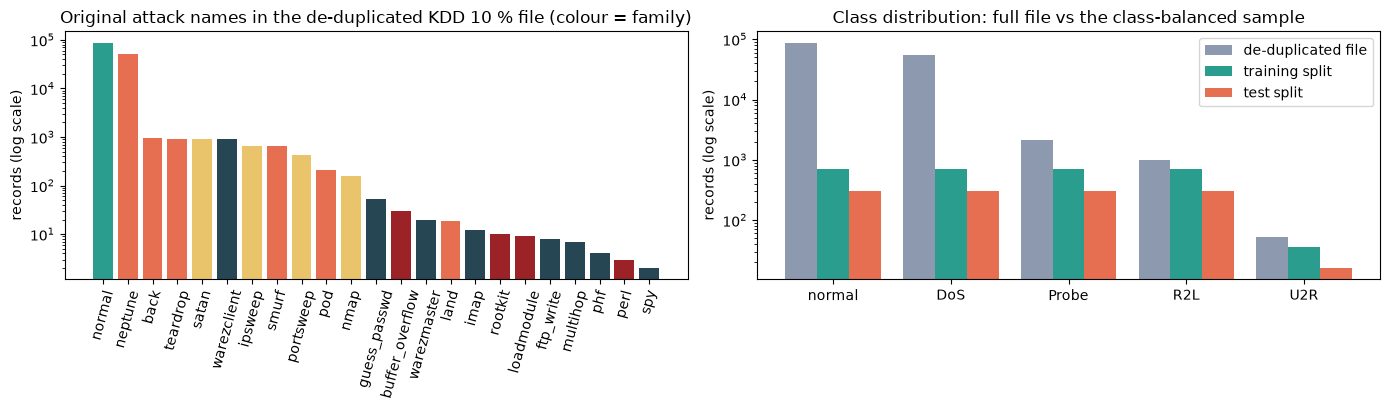

In [6]:
print("Dataset: KDD Cup 99, 10 % file")
print(f"  as downloaded: {n_raw:,} records x {len(KDD_COLUMNS)} features + label; after removing exact duplicates: {kdd.shape[0]:,} records")
print(f"  feature names ({len(KDD_COLUMNS)}): {KDD_COLUMNS}")
print(f"  categorical features: {CAT_COLS} with {[kdd[c].nunique() for c in CAT_COLS]} distinct values")
FAMILY_COLORS = {"normal": "#2a9d8f", "DoS": "#e76f51", "Probe": "#e9c46a", "R2L": "#264653", "U2R": "#9b2226"}
labels_tbl = (kdd.groupby(["family", "label"]).size().rename("records").reset_index()
                 .sort_values(["family", "records"], ascending=[True, False]).reset_index(drop=True))
print(f"  original label values ({kdd['label'].nunique()} names) and their counts:")
display(labels_tbl)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
lt = labels_tbl.sort_values("records", ascending=False)
axes[0].bar(lt["label"], lt["records"], color=[FAMILY_COLORS[f] for f in lt["family"]])
axes[0].set_yscale("log"); axes[0].set_ylabel("records (log scale)"); axes[0].tick_params(axis="x", rotation=75)
axes[0].set_title("Original attack names in the de-duplicated KDD 10 % file (colour = family)")
width = 0.27; xs = np.arange(len(CLASSES))
axes[1].bar(xs - width, [fam_after[c] for c in CLASSES], width, label="de-duplicated file", color="#8d99ae")
axes[1].bar(xs, [np.sum(y_train == k) for k in range(5)], width, label="training split", color="#2a9d8f")
axes[1].bar(xs + width, [np.sum(y_test == k) for k in range(5)], width, label="test split", color="#e76f51")
axes[1].set_yscale("log"); axes[1].set_xticks(xs); axes[1].set_xticklabels(CLASSES); axes[1].set_ylabel("records (log scale)")
axes[1].set_title("Class distribution: full file vs the class-balanced sample"); axes[1].legend()
plt.tight_layout(); plt.show()

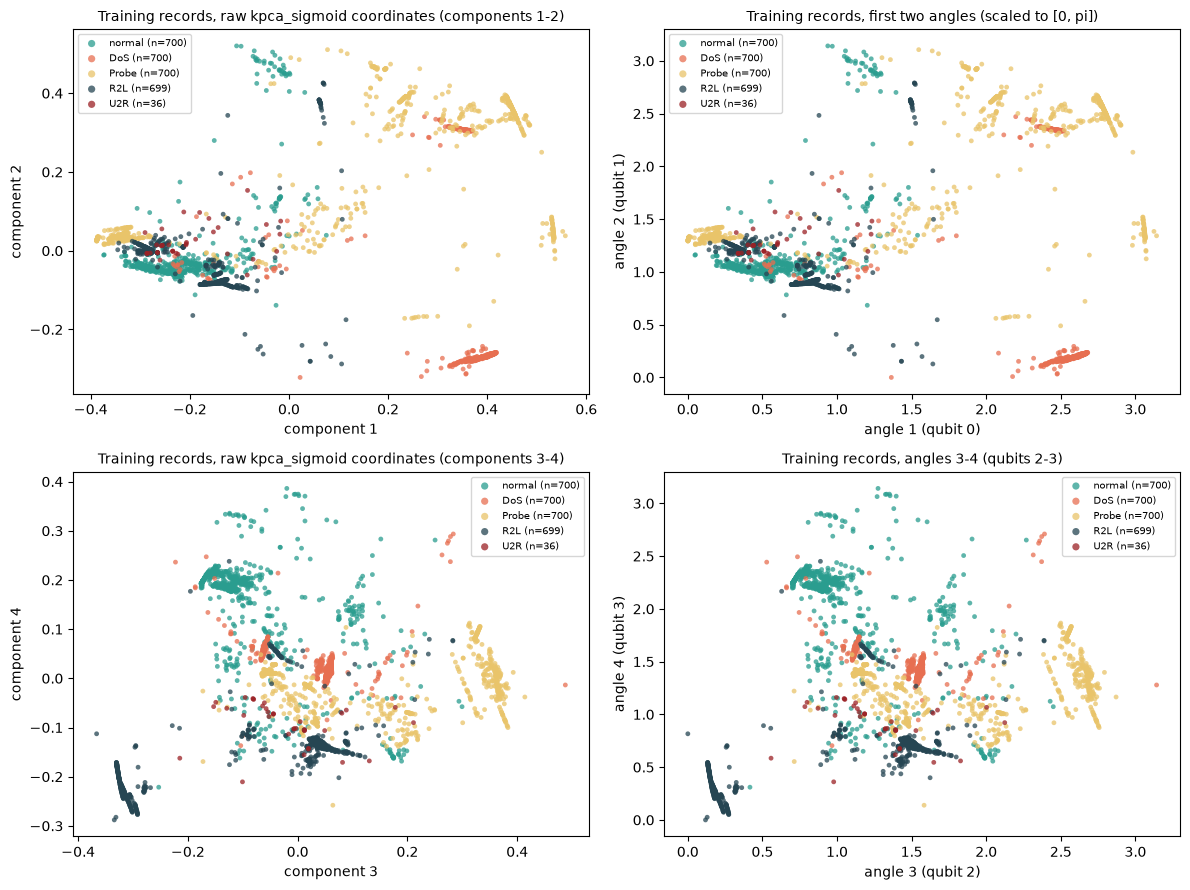

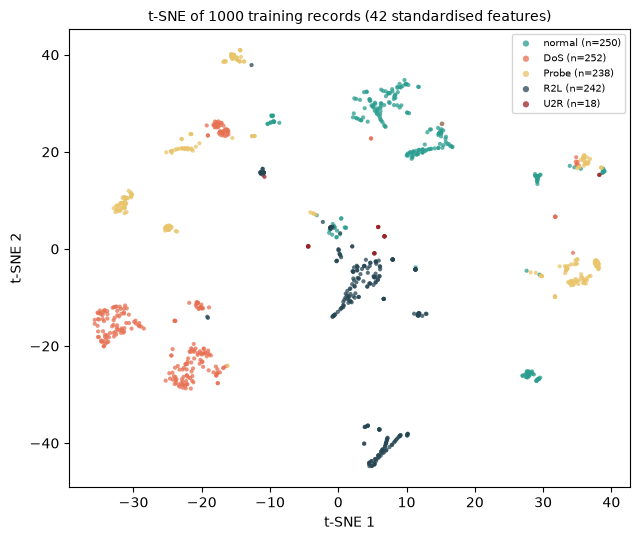

In [7]:
def scatter_by_class(ax, XY, y, title, xlabel, ylabel, s=12):
    for k, c in enumerate(CLASSES):
        m = y == k
        ax.scatter(XY[m, 0], XY[m, 1], s=s, alpha=0.75, color=FAMILY_COLORS[c], label=f"{c} (n={m.sum()})", edgecolors="none")
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.legend(fontsize=7, markerscale=1.5)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
scatter_by_class(axes[0, 0], P_train[:, :2], y_train, f"Training records, raw {REDUCER} coordinates (components 1-2)", "component 1", "component 2")
scatter_by_class(axes[0, 1], A_train[:, :2], y_train, "Training records, first two angles (scaled to [0, pi])", "angle 1 (qubit 0)", "angle 2 (qubit 1)")
scatter_by_class(axes[1, 0], P_train[:, 2:4], y_train, f"Training records, raw {REDUCER} coordinates (components 3-4)", "component 3", "component 4")
scatter_by_class(axes[1, 1], A_train[:, 2:4], y_train, "Training records, angles 3-4 (qubits 2-3)", "angle 3 (qubit 2)", "angle 4 (qubit 3)")
plt.tight_layout(); plt.show()

# labelled 2-D map of the 42 standardised features (paper Fig. 1 uses UMAP; t-SNE is the other method the paper names)
n_tsne = min(1000, len(Z_train)); sub = np.sort(np.random.default_rng(SEED).choice(len(Z_train), n_tsne, replace=False))
emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(Z_train[sub])
fig, ax = plt.subplots(figsize=(6.5, 5.5))
scatter_by_class(ax, emb, y_train[sub], f"t-SNE of {n_tsne} training records (42 standardised features)", "t-SNE 1", "t-SNE 2", s=9)
plt.tight_layout(); plt.show()

## 3. Classical baselines on identical inputs

The paper's classical SVMs use an RBF kernel and a polynomial kernel $K=(1+x\cdot z)^d$ (Eq. 10) on the reduced features. We train them (with the polynomial degree
$d=3$ and scikit-learn defaults otherwise; the paper gives no settings) on **exactly the 4 angles the quantum models will receive**, in two training
sizes: the small class-balanced training subset that the quantum models get, and the full training split. Added for a fair comparison: a random forest, and an
RBF-SVM whose `C` and `gamma` are chosen on the inner validation split of the training rows (the quantum kernel gets the same kind of tuning for its bandwidth in Section 6). As reference
for what the reduction costs, an RBF-SVM, a polynomial SVM and a random forest are also trained on all 42 standardised features.

Metrics: accuracy, macro precision / recall / F1 and **weighted F1** (the average weighted by class size; the paper does not say which F1 it reports, and its pair "accuracy 68 %, F1 68 %" for the RBF-SVM suggests the weighted one).
All numbers are on the same full test split.

In [8]:
def all_metrics(y, p):
    return dict(accuracy=accuracy_score(y, p),
                precision_macro=precision_score(y, p, average="macro", zero_division=0),
                recall_macro=recall_score(y, p, average="macro", zero_division=0),
                f1_macro=f1_score(y, p, average="macro", zero_division=0),
                f1_weighted=f1_score(y, p, average="weighted", zero_division=0))
METRIC_COLS = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted"]

def tune_rbf_svm(X, y):
    """CHOICE: (C, gamma) by accuracy on an inner stratified validation split of the given TRAINING rows."""
    a, b = train_test_split(np.arange(len(y)), test_size=VAL_FRACTION, stratify=y, random_state=SEED)
    best = None
    for C in SVM_C_GRID:
        for g in SVM_GAMMA_GRID:
            acc = accuracy_score(y[b], SVC(kernel="rbf", C=C, gamma=g).fit(X[a], y[a]).predict(X[b]))
            if best is None or acc > best[0]:
                best = (acc, C, g)
    return best

base_rows, base_preds = [], {}
def run_baseline(model_name, model, Xtr, ytr, Xte, inputs, note=""):
    t0 = time.perf_counter(); model.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(Xte); t_pred = time.perf_counter() - t0
    base_rows.append(dict(model=model_name, inputs=inputs, train_records=len(ytr), fit_s=t_fit, predict_s=t_pred, note=note, **all_metrics(y_test, pred)))
    base_preds[(model_name, inputs)] = pred

settings = [("4 angles, quantum training subset", A_q, y_q, A_test),
            ("4 angles, full training split", A_train, y_train, A_test),
            ("42 features, full training split", Z_train, y_train, Z_test)]
for inputs, Xtr, ytr, Xte in settings:
    run_baseline("SVM rbf (defaults)", SVC(kernel="rbf", random_state=SEED), Xtr, ytr, Xte, inputs)
    if inputs.startswith("4 angles"):
        v, C, g = tune_rbf_svm(Xtr, ytr)
        run_baseline("SVM rbf (tuned)", SVC(kernel="rbf", C=C, gamma=g, random_state=SEED), Xtr, ytr, Xte, inputs, f"C={C:g}, gamma={g:g}, inner-val acc {v:.3f}")
    run_baseline("SVM poly (1+x.z)^3", SVC(kernel="poly", degree=3, coef0=1.0, gamma=1.0, random_state=SEED), Xtr, ytr, Xte, inputs)
    run_baseline("RandomForest", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1), Xtr, ytr, Xte, inputs)
baseline_df = pd.DataFrame(base_rows)
display(baseline_df.set_index(["inputs", "model"])[["train_records"] + METRIC_COLS + ["fit_s", "note"]].round(3))

train_records  accuracy  precision_macro  recall_macro  f1_macro  f1_weighted  fit_s                                 note
inputs                            model                                                                                                                                        
4 angles, quantum training subset SVM rbf (defaults)            356     0.924            0.787         0.808     0.792        0.928  0.057                                     
                                  SVM rbf (tuned)               356     0.944            0.858         0.884     0.868        0.945  0.046  C=100, gamma=1, inner-val acc 0.966
                                  SVM poly (1+x.z)^3            356     0.931            0.824         0.849     0.834        0.932  0.038                                     
                                  RandomForest                  356     0.943            0.838         0.883     0.853        0.946  3.711                                     
4 angles, full training split     SVM rbf (defaults)           2835     0.947            0.759         0.768     0.763        0.941  0.406                                     
                                  SVM rbf (tuned)              2835     0.978            0.911         0.911     0.911        0.978  0.530  C=100, gamma=3, inner-val acc 0.970
                                  SVM poly (1+x.z)^3           2835     0.953            0.923         0.820     0.843        0.951  1.173                                     
                                  RandomForest                 2835     0.969            0.975         0.856     0.887        0.967  8.212                                     
42 features, full training split  SVM rbf (defaults)           2835     0.971            0.962         0.929     0.944        0.971  0.928                                     
                                  SVM poly (1+x.z)^3           2835     0.981            0.965         0.902     0.926        0.980  0.756                                     
                                  RandomForest                 2835     0.988            0.957         0.967     0.962        0.989  7.542

## 4. The hybrid neural network (HNN): Conv1D + LSTM + 4 dense layers

The architecture of the paper's Fig. 3 and Section III: the 42 standardised features are read as a sequence of **42 steps with one value each**. A `Conv1D` layer
(64 filters, kernel size 3) extracts local patterns, `MaxPooling1D(2)` halves the sequence, an `LSTM` layer (70 units, `return_sequences=True`) reads it as a sequence, `Flatten` turns the 3-D tensor into a vector, four `Dense` layers (1024, 768, 512, 256, ReLU, with batch normalisation and dropout as the text says) classify, and a final `Dense(5, softmax)` gives the five class probabilities.
Loss: categorical cross-entropy (Eq. 15); optimiser: Adam. An inner validation split of the training rows (not the test split) drives early stopping.
After training we compute, as the paper does, the accuracy, the multi-class AUC (Eq. 13: the average of the pairwise one-vs-one AUCs), the mean absolute error (Eq. 16: $\frac1N\sum_i\sum_j |y_{ij}-\hat y_{ij}|$ between the one-hot labels and the predicted probabilities) and the confusion matrix.

In [9]:
def build_hnn(seed):
    keras.utils.set_random_seed(seed)
    inp = keras.Input(shape=(N_SELECTED, 1))
    x = layers.Conv1D(64, 3, activation="relu")(inp)                  # paper: 1 Conv1D layer, 64 filters of size 3
    x = layers.MaxPooling1D(2)(x)                                     # paper: pool size 2
    x = layers.LSTM(70, return_sequences=True)(x)                     # paper: LSTM with 70 units, output processed as a sequence
    x = layers.Flatten()(x)
    for units in (1024, 768, 512, 256):                               # paper: four Dense ReLU layers with dropout (+ batch normalisation)
        x = layers.Dense(units, activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(HNN_DROPOUT)(x)
    out = layers.Dense(len(CLASSES), activation="softmax")(x)
    model = keras.Model(inp, out)
    model.compile(optimizer=keras.optimizers.Adam(HNN_LR), loss="categorical_crossentropy", metrics=["accuracy", "mae"])
    return model

build_hnn(SEED).summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 42, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 40, 64)         │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 20, 70)         │        37,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │     1,434,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 768)            │       787,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 768)            │         3,072 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       393,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,796,461 (10.67 MB)

 Trainable params: 2,791,341 (10.65 MB)

 Non-trainable params: 5,120 (20.00 KB)

In [10]:
Y_train_oh = np.eye(len(CLASSES))[y_train]; Y_test_oh = np.eye(len(CLASSES))[y_test]
Xh_train, Xh_test = Z_train[..., None], Z_test[..., None]

def eq16_mae(Y, P):
    return float(np.abs(Y - P).sum(axis=1).mean())            # paper Eq. 16: sum over classes, mean over samples

hnn_runs = {}
for seed in HNN_SEEDS:
    model = build_hnn(seed)
    t0 = time.perf_counter()
    hist = model.fit(Xh_train[inner_tr], Y_train_oh[inner_tr], validation_data=(Xh_train[inner_val], Y_train_oh[inner_val]),
                     epochs=HNN_EPOCHS, batch_size=HNN_BATCH, verbose=0, shuffle=True,
                     callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=HNN_PATIENCE, restore_best_weights=True)])
    t_fit = time.perf_counter() - t0
    proba = model.predict(Xh_test, verbose=0); pred = proba.argmax(1)
    m = all_metrics(y_test, pred)
    auc = roc_auc_score(y_test, proba, multi_class="ovo", average="macro", labels=list(range(len(CLASSES))))
    hnn_runs[seed] = dict(history=hist.history, proba=proba, pred=pred, auc=auc, mae16=eq16_mae(Y_test_oh, proba), fit_s=t_fit, epochs=len(hist.history["loss"]), **m)
    print(f"seed {seed}: {hnn_runs[seed]['epochs']} epochs in {t_fit:.0f} s | test accuracy {m['accuracy']:.4f} | weighted F1 {m['f1_weighted']:.4f} | "
          f"macro F1 {m['f1_macro']:.4f} | multi-class AUC (Eq. 13) {auc:.4f} | MAE (Eq. 16) {hnn_runs[seed]['mae16']:.4f}")
hnn_df = pd.DataFrame({s: {k: v for k, v in r.items() if k in METRIC_COLS + ["auc", "mae16", "fit_s", "epochs"]} for s, r in hnn_runs.items()}).T
print("HNN, mean +- std over seeds:"); display(hnn_df.agg(["mean", "std"]).round(4))

seed 42: 15 epochs in 974 s | test accuracy 0.9638 | weighted F1 0.9642 | macro F1 0.9114 | multi-class AUC (Eq. 13) 0.9975 | MAE (Eq. 16) 0.0884


seed 43: 15 epochs in 1606 s | test accuracy 0.9753 | weighted F1 0.9752 | macro F1 0.9547 | multi-class AUC (Eq. 13) 0.9967 | MAE (Eq. 16) 0.0604


HNN, mean +- std over seeds:


,auc,mae16,fit_s,epochs,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
mean,0.9971,0.0744,1290.4093,15.0,0.9696,0.9342,0.9339,0.9330,0.9697
std,0.0006,0.0198,446.9106,0.0,0.0081,0.0459,0.0150,0.0306,0.0078


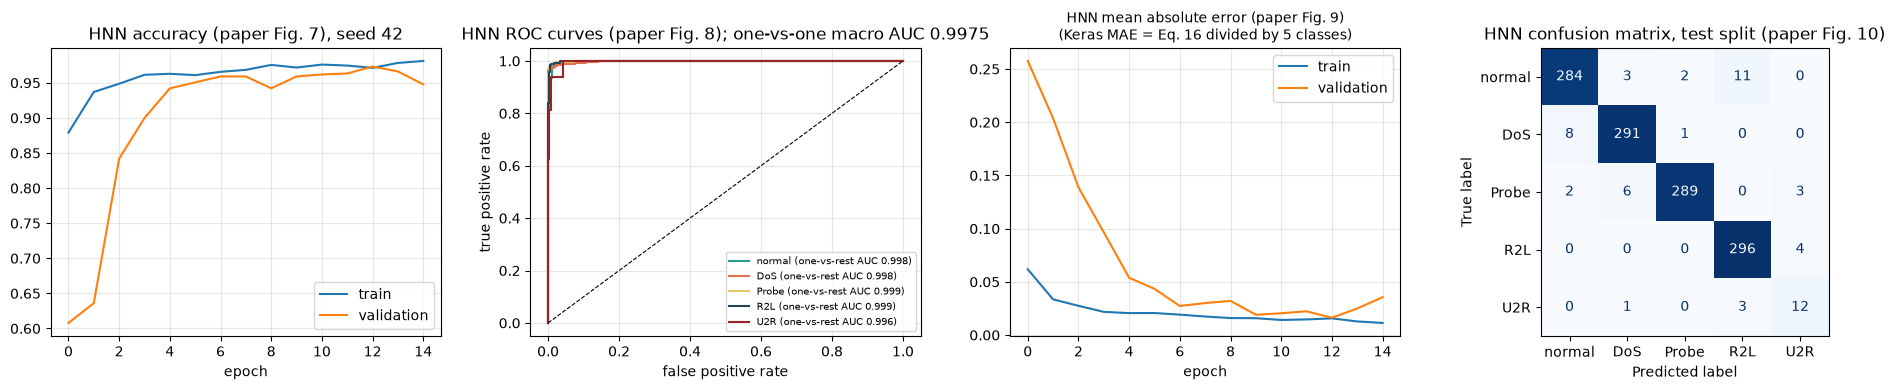

              precision    recall  f1-score   support

      normal      0.966     0.947     0.956       300
         DoS      0.967     0.970     0.968       300
       Probe      0.990     0.963     0.976       300
         R2L      0.955     0.987     0.970       300
         U2R      0.632     0.750     0.686        16

    accuracy                          0.964      1216
   macro avg      0.902     0.923     0.911      1216
weighted avg      0.965     0.964     0.964      1216



In [11]:
seed0 = HNN_SEEDS[0]; r0 = hnn_runs[seed0]; h = r0["history"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].plot(h["accuracy"], label="train"); axes[0].plot(h["val_accuracy"], label="validation")
axes[0].set_title(f"HNN accuracy (paper Fig. 7), seed {seed0}"); axes[0].set_xlabel("epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)
for k, c in enumerate(CLASSES):                                   # paper Fig. 8: ROC curves
    fpr, tpr, _ = roc_curve((y_test == k).astype(int), r0["proba"][:, k])
    axes[1].plot(fpr, tpr, color=FAMILY_COLORS[c], label=f"{c} (one-vs-rest AUC {roc_auc_score((y_test == k).astype(int), r0['proba'][:, k]):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=0.8); axes[1].set_title(f"HNN ROC curves (paper Fig. 8); one-vs-one macro AUC {r0['auc']:.4f}")
axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].legend(fontsize=7); axes[1].grid(alpha=0.3)
axes[2].plot(h["mae"], label="train"); axes[2].plot(h["val_mae"], label="validation")
axes[2].set_title("HNN mean absolute error (paper Fig. 9)\n(Keras MAE = Eq. 16 divided by 5 classes)", fontsize=10); axes[2].set_xlabel("epoch"); axes[2].legend(); axes[2].grid(alpha=0.3)
ConfusionMatrixDisplay(confusion_matrix(y_test, r0["pred"], labels=range(len(CLASSES))), display_labels=CLASSES).plot(ax=axes[3], colorbar=False, cmap="Blues")
axes[3].set_title("HNN confusion matrix, test split (paper Fig. 10)")
plt.tight_layout(); plt.show()
print(classification_report(y_test, r0["pred"], labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))

## Quantum Circuit Architecture

The paper gives no circuit diagram for its two quantum models: Eq. 11 says only that "a parameterized quantum circuit $U(x)$" encodes the data and Eq. 12 writes the VQC state as
$|\Theta(\vec x;\theta)\rangle = U_w(\theta)\,U_f(\vec x)|0\rangle$, a data-encoding unitary followed by a variational unitary. We therefore fix the following (every item is a `# CHOICE:` in the code and in the table at the top):

* **Qubits:** `N_QUBITS` = 4, one reduced feature per qubit (the paper: "very minimal features").
* **Data encoding $U_f(x)$ = feature map:** Qiskit `zz_feature_map(4, reps=2, entanglement="linear")`: Hadamards, one phase rotation $P(2x_i)$ per feature and a CNOT-phase-CNOT block per neighbouring pair with angle $2(\pi-x_i)(\pi-x_j)$, repeated twice. The **QSVM** uses exactly this circuit and nothing else: its kernel is the fidelity $|\langle\phi(x)|\phi(z)\rangle|^2$ of two such states.
* **Variational unitary $U_w(\theta)$ = ansatz (VQC only):** `real_amplitudes(4, reps=3)`: layers of $R_Y(\theta)$ rotations separated by a CNOT ladder, 16 trainable angles.
* **Read-out (VQC):** all four qubits are measured; the 4-bit outcome (an integer 0-15) is mapped to one of the five classes by Qiskit's default `x mod 5`, so the five outputs of the paper's Dense(5) layer correspond to the five classes.

The next cell builds the models with the same functions that the training code uses and draws the circuit object that is sent to the simulator: for the VQC the circuit stored inside `vqc.neural_network` (feature map + ansatz + measurements, with the
parameters named by the network), for the QSVM the feature map with one real training record bound to it. Qubits, depth after decomposition into basic gates and the number of trainable parameters are printed under the drawings.

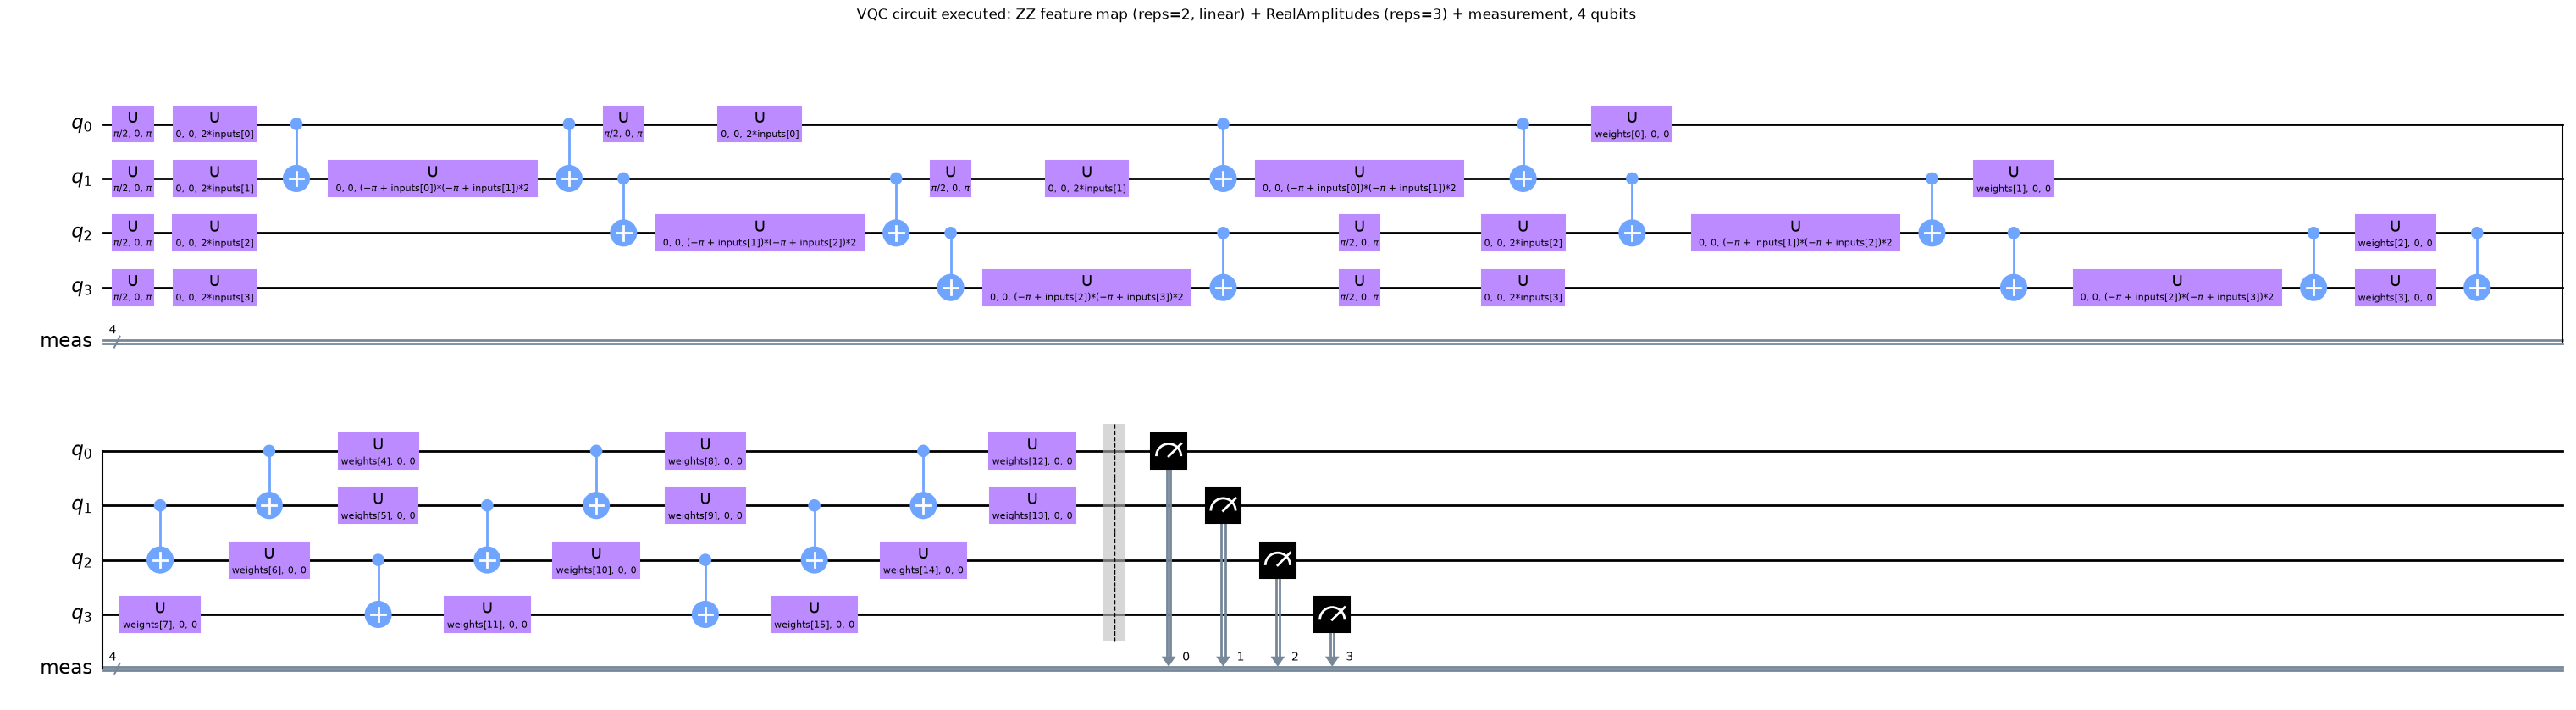

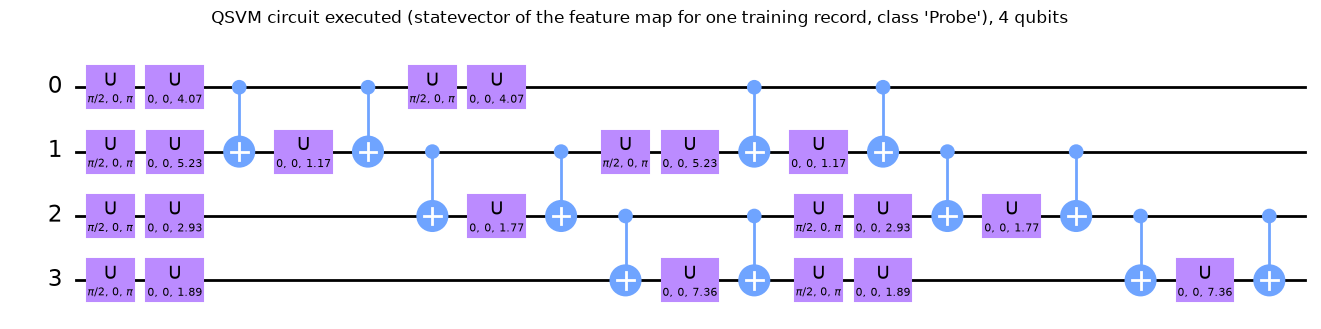

,qubits,depth_decomposed,trainable_parameters,input_parameters,two_qubit_gates
model,,,,,
VQC (feature map + ansatz + measurement),4,31,16,4,21
"QSVM (feature map only, no trainable gates)",4,19,0,4,12


Assumptions where the paper is silent: feature map (ZZ, 2 reps, linear entanglement), ansatz (RealAmplitudes, 3 reps), qubits (4), read-out (4-bit outcome mod 5 -> class), shots (1024), optimiser (COBYLA), initial angles (seeded uniform on [-pi, pi]).


In [12]:
def make_feature_map():
    return zz_feature_map(N_QUBITS, reps=FM_REPS, entanglement=ENTANGLEMENT)       # CHOICE: ZZ feature map, 2 repetitions, linear entanglement

def make_sampler(seed):
    # CHOICE: shot-based seeded sampler (Aer when available, else the reference StatevectorSampler)
    if USE_AER and AerSamplerV2 is not None:
        return AerSamplerV2(default_shots=SHOTS, seed=seed)
    return StatevectorSampler(default_shots=SHOTS, seed=seed)

def build_vqc(maxiter, seed, callback=None):
    """The single place where the VQC is constructed: used for the drawing below and for every training run."""
    ans = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS)                               # CHOICE: RealAmplitudes, 3 repetitions
    init = np.random.default_rng(seed).uniform(-np.pi, np.pi, ans.num_parameters)   # CHOICE: seeded random initial angles
    return VQC(feature_map=make_feature_map(), ansatz=ans, optimizer=COBYLA(maxiter=maxiter),
               sampler=make_sampler(seed), callback=callback, initial_point=init,
               output_shape=len(CLASSES))      # 5 outputs; this also sets the read-out to (bit-string mod 5), the default would be mod 2

# ---------- VQC: the circuit that is sent to the sampler ----------
vqc_demo = build_vqc(VQC_MAXITER, SEED)
qnn = vqc_demo.neural_network
vqc_circuit = getattr(qnn, "_circuit", None) or qnn.circuit.measure_all(inplace=False)
assert vqc_circuit.count_ops().get("measure", 0) == N_QUBITS and vqc_circuit.num_qubits == N_QUBITS
assert qnn.num_inputs == N_QUBITS and qnn.num_weights == real_amplitudes(N_QUBITS, reps=ANSATZ_REPS).num_parameters
assert vqc_demo.interpret(7) == 7 % len(CLASSES) and vqc_demo.interpret(14) == 14 % len(CLASSES)   # bit-string -> class, as described above
dec = vqc_circuit.decompose(reps=3)
fig = dec.draw("mpl", fold=45, style="clifford")
fig.suptitle(f"VQC circuit executed: ZZ feature map (reps={FM_REPS}, {ENTANGLEMENT}) + RealAmplitudes (reps={ANSATZ_REPS}) + measurement, {N_QUBITS} qubits", y=0.97)
display(fig); plt.close(fig)

# ---------- QSVM: the feature-map circuit the kernel executes, with one real training record bound ----------
fm_demo = make_feature_map()
example = A_q[0]
fm_bound = fm_demo.assign_parameters(list(map(float, example))).decompose(reps=3)
fig = fm_bound.draw("mpl", fold=45, style="clifford")
fig.suptitle(f"QSVM circuit executed (statevector of the feature map for one training record, class '{CLASSES[y_q[0]]}'), {N_QUBITS} qubits", y=0.95)
display(fig); plt.close(fig)

arch = pd.DataFrame([
    dict(model="VQC (feature map + ansatz + measurement)", qubits=vqc_circuit.num_qubits, depth_decomposed=dec.depth(),
         trainable_parameters=qnn.num_weights, input_parameters=qnn.num_inputs,
         two_qubit_gates=sum(n for g, n in dec.count_ops().items() if g in ("cx", "cz"))),
    dict(model="QSVM (feature map only, no trainable gates)", qubits=fm_bound.num_qubits, depth_decomposed=fm_bound.depth(),
         trainable_parameters=0, input_parameters=len(fm_demo.parameters),
         two_qubit_gates=sum(n for g, n in fm_bound.count_ops().items() if g in ("cx", "cz")))]).set_index("model")
display(arch)
print("Assumptions where the paper is silent: feature map (ZZ, 2 reps, linear entanglement), ansatz (RealAmplitudes, 3 reps), qubits (4), "
      "read-out (4-bit outcome mod 5 -> class), shots (%d), optimiser (COBYLA), initial angles (seeded uniform on [-pi, pi])." % SHOTS)

## 5. Quantum kernel SVM (QSVM): bandwidth, kernel, training

The kernel of Eq. 11 is the squared overlap of two feature-map states. With `reps = 2` and angles up to $\pi$ the ZZ terms $(\pi-x_i)(\pi-x_j)$ rotate by up to $2\pi^2$, so two records that differ a little already give almost orthogonal states and the kernel matrix collapses towards the identity. The paper does not mention
this; we multiply the angles by a **bandwidth** `scale` (a hyper-parameter, like `gamma` of the RBF kernel) chosen with `C` on an inner validation split of the **quantum training subset** only; the test split is never touched.

The kernel is computed two ways that must agree: **by hand** from `Statevector`s (one simulation per record, then $K=|S_aS_b^\dagger|^2$ by a matrix product), used for the tuning, and by Qiskit's `FidelityStatevectorKernel` inside `QSVC`, which gives the reported model.

C,1.0,10.0,100.0,mean_offdiagonal_kernel
scale,,,,
0.10,0.809,0.933,0.933,0.528
0.25,0.910,0.888,0.933,0.213
0.50,0.910,0.910,0.921,0.186
1.00,0.865,0.865,0.854,0.136


chosen on the inner validation split of the quantum training subset: scale = 0.1, C = 10


QSVC fit 25.8 s + predict 95.5 s on 356 training / 1216 test records | kernel check and prediction check passed (np.allclose / identical labels)


{'accuracy': 0.9202, 'precision_macro': 0.7834, 'recall_macro': 0.8052, 'f1_macro': 0.7862, 'f1_weighted': 0.9274}
              precision    recall  f1-score   support

      normal      0.917     0.923     0.920       300
         DoS      0.986     0.957     0.971       300
       Probe      0.925     0.947     0.936       300
         R2L      0.960     0.887     0.922       300
         U2R      0.128     0.312     0.182        16

    accuracy                          0.920      1216
   macro avg      0.783     0.805     0.786      1216
weighted avg      0.936     0.920     0.927      1216



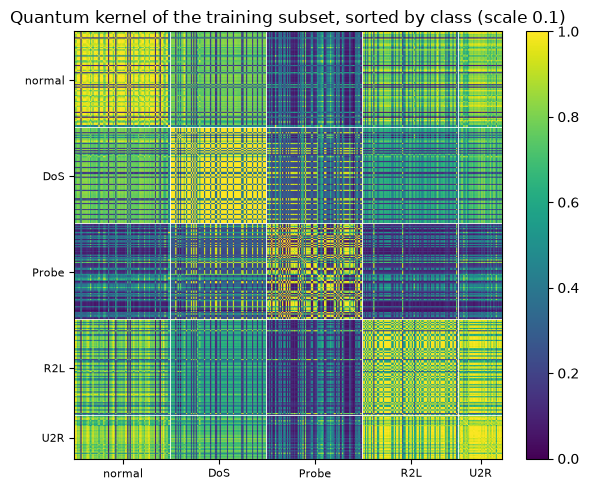

In [13]:
fm_q = make_feature_map()
def states(A, scale):
    return np.array([Statevector(fm_q.assign_parameters(list(map(float, scale * a)))).data for a in A])
def fidelity_kernel(Sa, Sb):
    return np.abs(Sa @ Sb.conj().T) ** 2                         # |<phi(a)|phi(b)>|^2  (paper Eq. 11)

qa, qb = train_test_split(np.arange(len(y_q)), test_size=VAL_FRACTION, stratify=y_q, random_state=SEED)   # inner split of the quantum subset
sweep = []
for scale in SCALE_GRID:
    S = states(A_q, scale); K = fidelity_kernel(S, S)
    for C in QSVM_C_GRID:
        acc = accuracy_score(y_q[qb], SVC(kernel="precomputed", C=C).fit(K[np.ix_(qa, qa)], y_q[qa]).predict(K[np.ix_(qb, qa)]))
        sweep.append(dict(scale=scale, C=C, inner_val_accuracy=acc, mean_offdiagonal=float(K[~np.eye(len(K), dtype=bool)].mean())))
sweep_df = pd.DataFrame(sweep)
best = max(sweep, key=lambda r: (r["inner_val_accuracy"], -r["C"], -r["scale"]))      # CHOICE: ties -> smaller C, then smaller bandwidth
QSVM_SCALE, QSVM_C = best["scale"], best["C"]
display(sweep_df.pivot(index="scale", columns="C", values="inner_val_accuracy").round(3).assign(
    mean_offdiagonal_kernel=sweep_df.groupby("scale")["mean_offdiagonal"].first().round(3)))
print(f"chosen on the inner validation split of the quantum training subset: scale = {QSVM_SCALE}, C = {QSVM_C:g}")

# final model: QSVC with Qiskit's FidelityStatevectorKernel on the scaled angles
t0 = time.perf_counter()
qkernel = FidelityStatevectorKernel(feature_map=make_feature_map())
qsvc = QSVC(quantum_kernel=qkernel, C=QSVM_C).fit(QSVM_SCALE * A_q, y_q)
t_fit_q = time.perf_counter() - t0
t0 = time.perf_counter(); pred_qsvm = qsvc.predict(QSVM_SCALE * A_test); t_pred_q = time.perf_counter() - t0
# verification: Qiskit's kernel equals the hand-made one, and so do the predictions
S_q, S_te = states(A_q, QSVM_SCALE), states(A_test, QSVM_SCALE)
K_q, K_te = fidelity_kernel(S_q, S_q), fidelity_kernel(S_te, S_q)
K_check = qkernel.evaluate(QSVM_SCALE * A_q[:25], QSVM_SCALE * A_q[:25])
assert np.allclose(K_check, K_q[:25, :25], atol=1e-8), "Qiskit kernel differs from the hand-made statevector kernel"
pred_hand = SVC(kernel="precomputed", C=QSVM_C).fit(K_q, y_q).predict(K_te)
assert (pred_hand == pred_qsvm).all(), "QSVC and the hand-made kernel SVM predict differently"
print(f"QSVC fit {t_fit_q:.1f} s + predict {t_pred_q:.1f} s on {len(y_q)} training / {len(y_test)} test records | kernel check and prediction check passed (np.allclose / identical labels)")
qsvm_metrics = all_metrics(y_test, pred_qsvm)
print({k: round(v, 4) for k, v in qsvm_metrics.items()})
print(classification_report(y_test, pred_qsvm, labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))

order = np.argsort(y_q, kind="stable"); bounds = np.cumsum(np.bincount(y_q, minlength=len(CLASSES)))
fig, ax = plt.subplots(figsize=(5.8, 5))
im = ax.imshow(K_q[np.ix_(order, order)], cmap="viridis", vmin=0, vmax=1)
for b in bounds[:-1]:
    ax.axhline(b - 0.5, color="w", lw=0.6); ax.axvline(b - 0.5, color="w", lw=0.6)
mid = bounds - np.diff(np.r_[0, bounds]) / 2
ax.set_xticks(mid); ax.set_xticklabels(CLASSES, fontsize=8); ax.set_yticks(mid); ax.set_yticklabels(CLASSES, fontsize=8)
ax.set_title(f"Quantum kernel of the training subset, sorted by class (scale {QSVM_SCALE})"); fig.colorbar(im, fraction=0.046)
plt.tight_layout(); plt.show()

## 6. Variational quantum classifier (VQC): training with COBYLA

The VQC minimises the cross-entropy between the class probabilities of the circuit and the one-hot labels (Eq. 17 is its two-class form) over the 16 angles of the ansatz. COBYLA is a derivative-free optimiser; its first `n_parameters + 1` = 17 evaluations build the initial simplex, then each iteration
is one pass of the whole training subset through the circuit. The paper's Fig. 4 plots cost against steps; we record the cost at every evaluation (and redraw the curve every `PLOT_EVERY` evaluations for the first seed).
The VQC receives the angles scaled by the **same bandwidth** that the QSVM selected on training data (a choice: the paper does not scale its features, and with the full angle range the 2-repetition ZZ map gives a nearly random encoding).

**A fast but exact simulation of the Qiskit `VQC`.** Qiskit's `VQC` sends every training record through a shot-based sampler at every optimiser step; on a CPU that costs about 0.1 s per record and step, i.e. hours for the budgets below. The circuit is
$U_w(\theta)\,U_f(x)\,|0\rangle$ (Eq. 12), so the feature-map states $U_f(x)|0\rangle$ do not depend on $\theta$: they were already computed with Qiskit's `Statevector` in Section 5, and for each $\theta$ Qiskit's `Operator` gives the 16 x 16 matrix of the ansatz. The probability of each 4-bit outcome is $|U_w(\theta)\,U_f(x)|0\rangle|^2$ (exact, the limit of infinitely many shots), the outcome integer is mapped to a class by `x mod 5` (what `VQC` does), and the
loss is Qiskit's own `CrossEntropyLoss` averaged over the records (what `VQC` minimises). Before any training, the cell below **asserts that these probabilities equal those of the full circuit object stored inside the Qiskit `VQC`** (`np.allclose`), and after training the trained angles are sent through the real Qiskit `VQC` network
(Aer sampler, `SHOTS` shots) on a subset of the test records to check that its class probabilities and predicted labels agree.

*Reading the outputs of the next cell:* the cell redraws the live cost curve with `clear_output`, which also erases the lines it printed before (the confirmation line of the equivalence assertion and the per-seed summaries of all seeds but the last).
The assertion itself raises an error if it fails, and the cell finished without error; the per-seed metrics and the shot-based check (`shot_mean_abs_dev` = mean absolute difference between the exact and the shot-based class probabilities, `shot_label_agreement` = share of identical predicted labels)
are kept in the table printed by the cell.

In [14]:
ansatz_q = real_amplitudes(N_QUBITS, reps=ANSATZ_REPS)                       # the same ansatz function as build_vqc
CLASS_MAP = np.zeros((2 ** N_QUBITS, len(CLASSES)))
CLASS_MAP[np.arange(2 ** N_QUBITS), np.arange(2 ** N_QUBITS) % len(CLASSES)] = 1.0     # outcome integer -> class (x mod 5), as in VQC
ce_loss = CrossEntropyLoss()                                                 # Qiskit's own loss, as used by VQC
Y_q_oh = np.eye(len(CLASSES))[y_q]

def ansatz_unitary(theta):
    return Operator(ansatz_q.assign_parameters(list(map(float, theta)))).data
def outcome_probabilities(S, theta):          # |U_w(theta) U_f(x)|0>|^2 for every row of S (feature-map states)
    return np.abs(S @ ansatz_unitary(theta).T) ** 2
def class_probabilities(S, theta):
    return outcome_probabilities(S, theta) @ CLASS_MAP
def vqc_objective(theta, S, Y):               # what VQC minimises: sum of the per-record cross-entropy / number of records
    return float(np.sum(ce_loss.evaluate(class_probabilities(S, theta), Y)) / len(Y))

# ---- assertion: the exact engine equals the full circuit object inside the Qiskit VQC ----
chk_rng = np.random.default_rng(SEED)
qnn_v = build_vqc(VQC_MAXITER, SEED).neural_network
max_err = 0.0
for _ in range(8):
    th = chk_rng.uniform(-np.pi, np.pi, ansatz_q.num_parameters); k = int(chk_rng.integers(len(S_q)))
    full = qnn_v.circuit.assign_parameters({**dict(zip(qnn_v.input_params, map(float, QSVM_SCALE * A_q[k]))),
                                            **dict(zip(qnn_v.weight_params, map(float, th)))})
    p_ref = Statevector(full).probabilities()                       # 16 outcome probabilities of the real circuit
    p_mine = outcome_probabilities(S_q[k:k + 1], th)[0]
    max_err = max(max_err, float(np.abs(p_ref - p_mine).max()))
    assert np.allclose(p_ref, p_mine, atol=1e-10), "exact engine differs from the Qiskit circuit"
print(f"exact engine == Qiskit circuit for 8 random (record, angles) pairs: max |difference| = {max_err:.2e}")

vqc_runs = {}
for seed in VQC_SEEDS:
    losses = []; live = (seed == VQC_SEEDS[0])
    def fun(theta, losses=losses, live=live, seed=seed):
        v = vqc_objective(theta, S_q, Y_q_oh); losses.append(v)
        if live and len(losses) % PLOT_EVERY == 0:
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(6.5, 3.2)); ax.plot(losses); ax.set_xlabel("objective evaluation (step)"); ax.set_ylabel("cross-entropy cost")
            ax.set_title(f"VQC training, seed {seed}: evaluation {len(losses)} / {VQC_MAXITER}"); ax.grid(alpha=0.3); plt.show()
        return v
    theta0 = np.random.default_rng(seed).uniform(-np.pi, np.pi, ansatz_q.num_parameters)      # the initial point build_vqc uses
    t0 = time.perf_counter(); res = COBYLA(maxiter=VQC_MAXITER).minimize(fun=fun, x0=theta0); t_fit = time.perf_counter() - t0
    theta = np.asarray(res.x)
    pred = class_probabilities(S_te, theta).argmax(1)
    train_acc = accuracy_score(y_q, class_probabilities(S_q, theta).argmax(1))
    # end-to-end check through the real Qiskit VQC network (shot-based Aer sampler) on a subset of the test records
    sub = np.sort(np.random.default_rng(seed).choice(len(y_test), size=min(N_SHOT_CHECK, len(y_test)), replace=False))
    t0 = time.perf_counter(); p_shots = build_vqc(VQC_MAXITER, seed).neural_network.forward(QSVM_SCALE * A_test[sub], theta); t_chk = time.perf_counter() - t0
    p_exact = class_probabilities(S_te[sub], theta)
    shot_dev, shot_agree = float(np.abs(p_shots - p_exact).mean()), float((p_shots.argmax(1) == p_exact.argmax(1)).mean())
    vqc_runs[seed] = dict(losses=losses, pred=pred, theta=theta, fit_s=t_fit, train_accuracy=train_acc, n_eval=len(losses),
                          shot_mean_abs_dev=shot_dev, shot_label_agreement=shot_agree, **all_metrics(y_test, pred))
    clear_output(wait=True)
    print(f"seed {seed}: {len(losses)} objective evaluations, cost {losses[0]:.3f} -> {losses[-1]:.3f} (min {min(losses):.3f}) | fit {t_fit:.1f} s | "
          f"train accuracy {train_acc:.3f} | test accuracy {vqc_runs[seed]['accuracy']:.4f}, weighted F1 {vqc_runs[seed]['f1_weighted']:.4f}, macro F1 {vqc_runs[seed]['f1_macro']:.4f}")
    print(f"   real Qiskit VQC network, {SHOTS} shots, {len(sub)} test records ({t_chk:.0f} s): mean |p_shots - p_exact| = {shot_dev:.4f}, predicted labels agree for {shot_agree:.1%}")
vqc_df = pd.DataFrame({s: {k: v for k, v in r.items() if k in METRIC_COLS + ["train_accuracy", "fit_s", "n_eval", "shot_mean_abs_dev", "shot_label_agreement"]} for s, r in vqc_runs.items()}).T
print(); print("VQC per seed:"); display(vqc_df.round(4)); print("VQC mean +- std over seeds:"); display(vqc_df.agg(["mean", "std"]).round(4))

seed 46: 300 objective evaluations, cost 2.771 -> 1.748 (min 1.748) | fit 32.9 s | train accuracy 0.534 | test accuracy 0.5822, weighted F1 0.5593, macro F1 0.4534
   real Qiskit VQC network, 1024 shots, 100 test records (3 s): mean |p_shots - p_exact| = 0.0091, predicted labels agree for 100.0%

VQC per seed:


,fit_s,train_accuracy,n_eval,shot_mean_abs_dev,shot_label_agreement,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
42,62.3157,0.7275,300.0,0.0094,0.97,0.8150,0.6612,0.6607,0.6570,0.8104
43,18.1171,0.7416,300.0,0.0093,0.99,0.8273,0.6660,0.6707,0.6665,0.8222
44,20.9958,0.6517,300.0,0.0089,0.93,0.7336,0.5944,0.5947,0.5873,0.7244
45,22.9933,0.6601,300.0,0.0092,0.91,0.7442,0.6353,0.6033,0.5820,0.7179
46,32.8955,0.5337,300.0,0.0091,1.00,0.5822,0.4705,0.4720,0.4534,0.5593


VQC mean +- std over seeds:


,fit_s,train_accuracy,n_eval,shot_mean_abs_dev,shot_label_agreement,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
mean,31.4635,0.6629,300.0,0.0092,0.9600,0.7405,0.6055,0.6003,0.5892,0.7268
std,18.1201,0.0824,0.0,0.0002,0.0387,0.0977,0.0806,0.0792,0.0853,0.1052


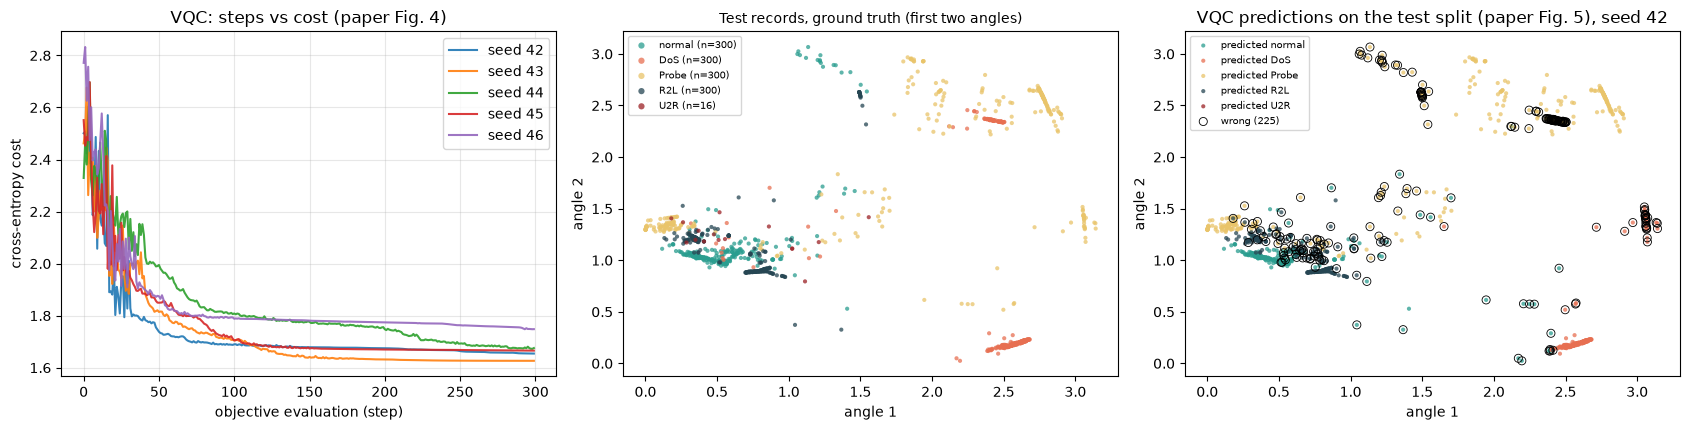

              precision    recall  f1-score   support

      normal      0.885     0.773     0.826       300
         DoS      0.878     0.747     0.807       300
       Probe      0.690     0.860     0.766       300
         R2L      0.852     0.923     0.886       300
         U2R      0.000     0.000     0.000        16

    accuracy                          0.815      1216
   macro avg      0.661     0.661     0.657      1216
weighted avg      0.816     0.815     0.810      1216



In [15]:
seed0 = VQC_SEEDS[0]; v0 = vqc_runs[seed0]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for s, r in vqc_runs.items():
    axes[0].plot(r["losses"], label=f"seed {s}", alpha=0.9)
axes[0].set_xlabel("objective evaluation (step)"); axes[0].set_ylabel("cross-entropy cost"); axes[0].set_title("VQC: steps vs cost (paper Fig. 4)"); axes[0].legend(); axes[0].grid(alpha=0.3)
scatter_by_class(axes[1], A_test[:, :2], y_test, "Test records, ground truth (first two angles)", "angle 1", "angle 2", s=9)
wrong = v0["pred"] != y_test
for k, c in enumerate(CLASSES):
    m = v0["pred"] == k
    axes[2].scatter(A_test[m, 0], A_test[m, 1], s=9, alpha=0.75, color=FAMILY_COLORS[c], label=f"predicted {c}", edgecolors="none")
axes[2].scatter(A_test[wrong, 0], A_test[wrong, 1], s=34, facecolors="none", edgecolors="k", linewidths=0.6, label=f"wrong ({wrong.sum()})")
axes[2].set_title(f"VQC predictions on the test split (paper Fig. 5), seed {seed0}"); axes[2].set_xlabel("angle 1"); axes[2].set_ylabel("angle 2"); axes[2].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(classification_report(y_test, v0["pred"], labels=range(len(CLASSES)), target_names=CLASSES, digits=3, zero_division=0))

## 7. All models side by side

One table with the test-split metrics of every model, then the confusion matrices of the quantum models and of the two SVMs on the same inputs, and a bar chart of the accuracy of each model next to the number the paper states.

,train_records,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
model,,,,,,
"HNN (Conv1D+LSTM+DNN), 42 steps",2126,0.9696,0.9342,0.9339,0.9330,0.9697
"SVM rbf (defaults) | 4 angles, full training split",2835,0.9474,0.7587,0.7680,0.7631,0.9413
"SVM poly (1+x.z)^3 | 4 angles, full training split",2835,0.9531,0.9232,0.8200,0.8427,0.9506
"SVM rbf (tuned) | 4 angles, full training split",2835,0.9778,0.9110,0.9110,0.9110,0.9778
"RandomForest | 4 angles, full training split",2835,0.9688,0.9750,0.8563,0.8872,0.9670
"SVM rbf (defaults) | 4 angles, quantum training subset",356,0.9235,0.7868,0.8078,0.7920,0.9283
"SVM poly (1+x.z)^3 | 4 angles, quantum training subset",356,0.9309,0.8242,0.8493,0.8336,0.9325
"SVM rbf (tuned) | 4 angles, quantum training subset",356,0.9441,0.8579,0.8837,0.8685,0.9451
"RandomForest | 4 angles, quantum training subset",356,0.9433,0.8376,0.8830,0.8528,0.9459


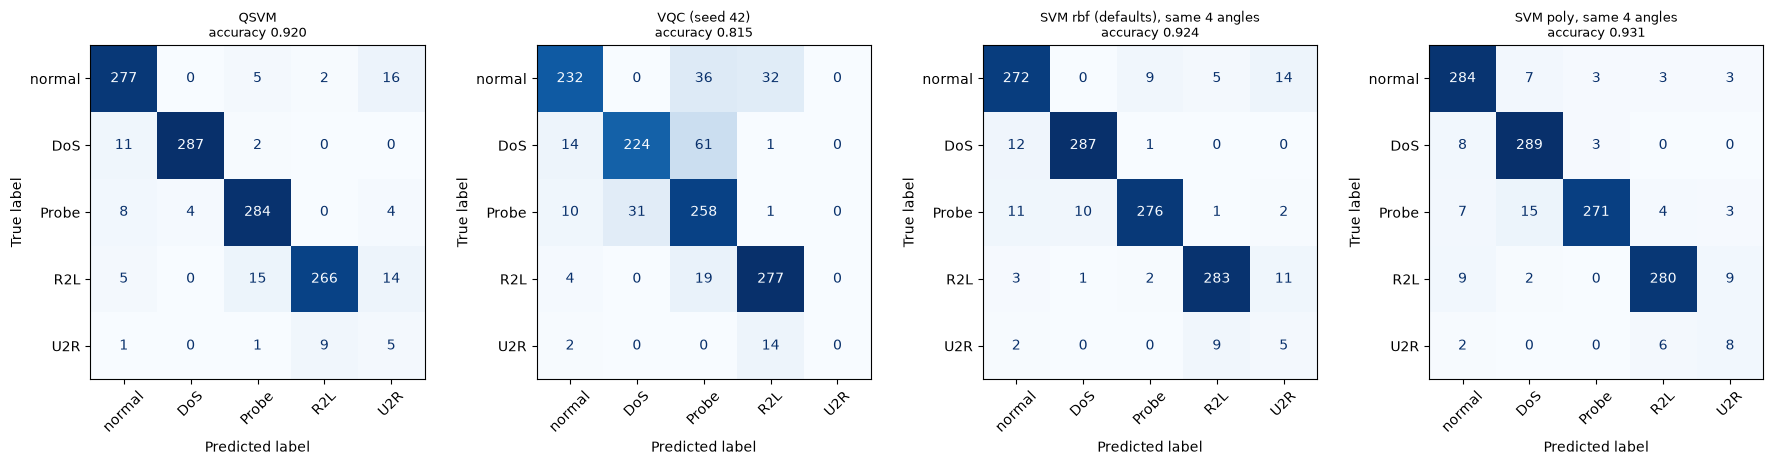

In [16]:
def bl(model, inputs): return baseline_df[(baseline_df.model == model) & (baseline_df.inputs == inputs)].iloc[0]
IN_Q, IN_F, IN_Z = "4 angles, quantum training subset", "4 angles, full training split", "42 features, full training split"
rows = []
rows.append(dict(model="HNN (Conv1D+LSTM+DNN), 42 steps", train_records=int(len(inner_tr)), **{m: float(np.mean([r[m] for r in hnn_runs.values()])) for m in METRIC_COLS}))
for name, inp in [("SVM rbf (defaults)", IN_F), ("SVM poly (1+x.z)^3", IN_F), ("SVM rbf (tuned)", IN_F), ("RandomForest", IN_F),
                  ("SVM rbf (defaults)", IN_Q), ("SVM poly (1+x.z)^3", IN_Q), ("SVM rbf (tuned)", IN_Q), ("RandomForest", IN_Q), ("SVM rbf (defaults)", IN_Z), ("RandomForest", IN_Z)]:
    b = bl(name, inp); rows.append(dict(model=f"{name} | {inp}", train_records=int(b.train_records), **{m: float(b[m]) for m in METRIC_COLS}))
rows.append(dict(model="QSVM (ZZ kernel, QSVC)", train_records=len(y_q), **qsvm_metrics))
rows.append(dict(model=f"VQC (ZZ + RealAmplitudes, COBYLA) mean of {len(VQC_SEEDS)} seed(s)", train_records=len(y_q), **{m: float(vqc_df[m].mean()) for m in METRIC_COLS}))
summary = pd.DataFrame(rows).set_index("model")
display(summary.round(4))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (name, pred) in zip(axes, [("QSVM", pred_qsvm), (f"VQC (seed {seed0})", v0["pred"]),
                                    ("SVM rbf (defaults), same 4 angles", base_preds[("SVM rbf (defaults)", IN_Q)]),
                                    ("SVM poly, same 4 angles", base_preds[("SVM poly (1+x.z)^3", IN_Q)])]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=range(len(CLASSES))), display_labels=CLASSES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_test, pred):.3f}", fontsize=9); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 8. Paper versus this notebook

Each row is one number the paper states in its text (Section III and IV). The verdict is **reproduced** when our value is within 0.02 of the paper's (two accuracy points, 0.02 in F1), **exceeded** when it is more than 0.02 above, **not reached** when more than 0.02 below.
The paper's SVM numbers are compared with our SVMs trained on the full training split (rows marked *counted*); the same SVMs trained on the quantum training subset (identical training records as the quantum models) are listed for information.
F1 is compared as **weighted F1**; the macro F1 is shown next to it. The figures 7-10 (HNN accuracy curve, AUC, MAE, confusion matrix) carry no numbers in the paper's text and so cannot be checked numerically.

,claim,paper,notebook,verdict,counted,remark
0,HNN accuracy over the five classes (79.4 %),0.794,0.9696,exceeded,True,"mean of 2 seed(s); macro F1 0.933, AUC 0.997"
1,"SVM rbf accuracy, full training split (68 %)",0.680,0.9474,exceeded,True,
2,"SVM rbf F1 (weighted), full training split (68 %)",0.680,0.9413,exceeded,True,macro F1 0.763
3,"SVM rbf accuracy, quantum training subset (68 %)",0.680,0.9235,exceeded,False,
4,"SVM rbf F1 (weighted), quantum training subset...",0.680,0.9283,exceeded,False,macro F1 0.792
5,"SVM poly accuracy, full training split (75 %)",0.750,0.9531,exceeded,True,
6,"SVM poly F1 (weighted), full training split (6...",0.660,0.9506,exceeded,True,macro F1 0.843
7,"SVM poly accuracy, quantum training subset (75 %)",0.750,0.9309,exceeded,False,
8,"SVM poly F1 (weighted), quantum training subse...",0.660,0.9325,exceeded,False,macro F1 0.834
9,QSVM accuracy (64 %),0.640,0.9202,exceeded,True,


Verdict counts (counted rows only): {'exceeded': 8}


,claim,paper,notebook,verdict
0,HNN is more accurate than the QSVM (79.4 vs 64),+0.154,+0.0493,reproduced (same direction)
1,HNN is more accurate than the VQC (79.4 vs 60),+0.194,+0.2291,reproduced (same direction)
2,QSVM is more accurate than the VQC (64 vs 60),+0.040,+0.1798,reproduced (same direction)
3,QSVM below the RBF-SVM on the same training re...,-0.040,-0.0033,tie (within 1 point)
4,"Polynomial SVM above the RBF SVM (75 vs 68), f...",+0.070,+0.0058,tie (within 1 point)
5,HNN is the best of all five paper models,yes,HNN 0.9696 vs best other 0.9885 (all rows of S...,reproduced
6,HNN AUC / MAE / confusion matrix (Figs. 8-10),figures only,"AUC 0.9971, MAE (Eq. 16) 0.0744",cannot be checked (no numbers in the text)
7,Quantum models detect network intrusions 'as s...,60 % / 64 %,"VQC 0.740, QSVM 0.920",see the reading below


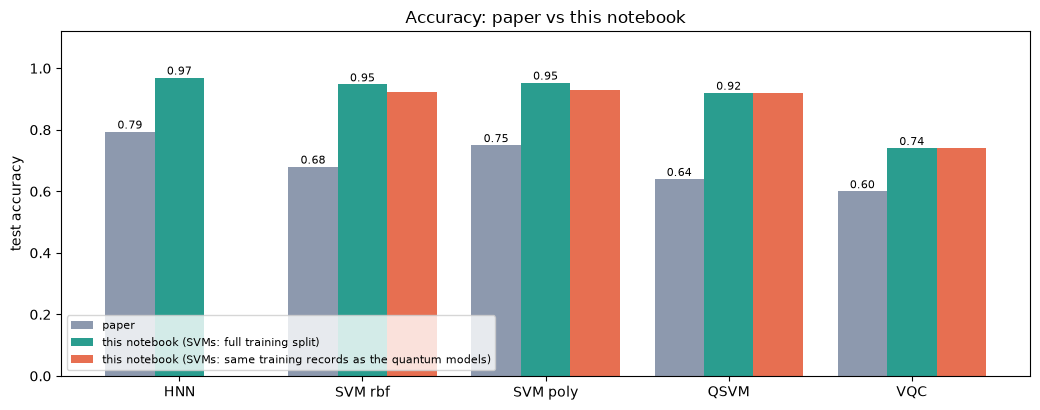

In [17]:
TOL = 0.02
def verdict(paper, ours, tol=TOL):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)):
        return "not run here"
    if abs(ours - paper) <= tol:
        return "reproduced"
    return "exceeded" if ours > paper else "not reached"

hnn_acc = float(np.mean([r["accuracy"] for r in hnn_runs.values()]))
vqc_acc = float(vqc_df["accuracy"].mean())
rows = []
def add(claim, paper, ours, counted=True, extra=""):
    rows.append(dict(claim=claim, paper=paper, notebook=None if ours is None else round(float(ours), 4), verdict=verdict(paper, ours), counted=counted, remark=extra))

add("HNN accuracy over the five classes (79.4 %)", 0.794, hnn_acc, extra=f"mean of {len(HNN_SEEDS)} seed(s); macro F1 {np.mean([r['f1_macro'] for r in hnn_runs.values()]):.3f}, AUC {np.mean([r['auc'] for r in hnn_runs.values()]):.3f}")
for model, pa, pf in [("SVM rbf (defaults)", 0.68, 0.68), ("SVM poly (1+x.z)^3", 0.75, 0.66)]:
    for inp, counted in [(IN_F, True), (IN_Q, False)]:
        b = bl(model, inp); tag = "full training split" if counted else "quantum training subset"
        add(f"{model.split(' (')[0]} accuracy, {tag} ({int(pa*100)} %)", pa, b.accuracy, counted)
        add(f"{model.split(' (')[0]} F1 (weighted), {tag} ({int(pf*100)} %)", pf, b.f1_weighted, counted, extra=f"macro F1 {b.f1_macro:.3f}")
add("QSVM accuracy (64 %)", 0.64, qsvm_metrics["accuracy"])
add("QSVM F1 (weighted) (45 %)", 0.45, qsvm_metrics["f1_weighted"], extra=f"macro F1 {qsvm_metrics['f1_macro']:.3f}")
add("VQC accuracy (60 %)", 0.60, vqc_acc, extra=f"mean of {len(VQC_SEEDS)} seed(s), std {vqc_df['accuracy'].std(ddof=0):.3f}")
comparison = pd.DataFrame(rows)
display(comparison)
cnt = comparison[comparison.counted]["verdict"].value_counts().to_dict()
print("Verdict counts (counted rows only):", cnt)

# qualitative claims, judged on the sign of the gap with a 1-point tie band
def sign_claim(text, a, b, paper_gap):
    gap = a - b
    if abs(gap) < 0.01:
        v = "tie (within 1 point)"
    else:
        v = "reproduced (same direction)" if np.sign(gap) == np.sign(paper_gap) else "not reproduced (opposite direction)"
    return dict(claim=text, paper=f"{paper_gap:+.3f}", notebook=f"{gap:+.4f}", verdict=v)
q_rbf, q_poly = bl("SVM rbf (defaults)", IN_Q).accuracy, bl("SVM poly (1+x.z)^3", IN_Q).accuracy
f_rbf, f_poly = bl("SVM rbf (defaults)", IN_F).accuracy, bl("SVM poly (1+x.z)^3", IN_F).accuracy
best_other = max(summary.drop(index=[i for i in summary.index if i.startswith("HNN")])["accuracy"])
claims = [
    sign_claim("HNN is more accurate than the QSVM (79.4 vs 64)", hnn_acc, qsvm_metrics["accuracy"], 0.794 - 0.64),
    sign_claim("HNN is more accurate than the VQC (79.4 vs 60)", hnn_acc, vqc_acc, 0.794 - 0.60),
    sign_claim("QSVM is more accurate than the VQC (64 vs 60)", qsvm_metrics["accuracy"], vqc_acc, 0.64 - 0.60),
    sign_claim("QSVM below the RBF-SVM on the same training records (64 vs 68)", qsvm_metrics["accuracy"], q_rbf, 0.64 - 0.68),
    sign_claim("Polynomial SVM above the RBF SVM (75 vs 68), full training split", f_poly, f_rbf, 0.75 - 0.68),
    dict(claim="HNN is the best of all five paper models", paper="yes", notebook=f"HNN {hnn_acc:.4f} vs best other {best_other:.4f} (all rows of Section 7, incl. our extra baselines)",
         verdict="reproduced" if hnn_acc >= max(f_rbf, f_poly, qsvm_metrics['accuracy'], vqc_acc) else "not reproduced"),
    dict(claim="HNN AUC / MAE / confusion matrix (Figs. 8-10)", paper="figures only", notebook=f"AUC {np.mean([r['auc'] for r in hnn_runs.values()]):.4f}, MAE (Eq. 16) {np.mean([r['mae16'] for r in hnn_runs.values()]):.4f}", verdict="cannot be checked (no numbers in the text)"),
    dict(claim="Quantum models detect network intrusions 'as stand-alone systems'", paper="60 % / 64 %", notebook=f"VQC {vqc_acc:.3f}, QSVM {qsvm_metrics['accuracy']:.3f}", verdict="see the reading below"),
]
display(pd.DataFrame(claims))

fig, ax = plt.subplots(figsize=(10.5, 4.2))
names = ["HNN", "SVM rbf", "SVM poly", "QSVM", "VQC"]
paper_acc = [0.794, 0.68, 0.75, 0.64, 0.60]
our_acc = [hnn_acc, f_rbf, f_poly, qsvm_metrics["accuracy"], vqc_acc]
our_acc_q = [np.nan, q_rbf, q_poly, qsvm_metrics["accuracy"], vqc_acc]
x = np.arange(len(names)); w = 0.27
ax.bar(x - w, paper_acc, w, label="paper", color="#8d99ae"); ax.bar(x, our_acc, w, label="this notebook (SVMs: full training split)", color="#2a9d8f")
ax.bar(x + w, our_acc_q, w, label="this notebook (SVMs: same training records as the quantum models)", color="#e76f51")
for xi, (p, o) in enumerate(zip(paper_acc, our_acc)):
    ax.text(xi - w, p + 0.01, f"{p:.2f}", ha="center", fontsize=8); ax.text(xi, o + 0.01, f"{o:.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(names); ax.set_ylim(0, 1.12); ax.set_ylabel("test accuracy"); ax.set_title("Accuracy: paper vs this notebook"); ax.legend(fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

## Reading the paper critically

**Every number the paper states is exceeded, by 15 to 30 points.** On the KDD Cup 99 records of this notebook (de-duplicated, class-balanced, 4,051 records, 1,216 of them in the test split) the RBF-SVM scores 94.7 % (paper 68 %), the polynomial SVM 95.3 % (75 %), the QSVM 92.0 % (64 %), the mean VQC 74.1 % (60 %) and the HNN 97.0 % (79.4 %); eight of eight counted verdicts are "exceeded".
KDD Cup 99 is an easy benchmark: a random forest on the 42 selected features reaches 98.9 %, and even four kernel-PCA components with a tuned RBF-SVM reach 97.8 %. Scores of 60 to 79 % on this data point to something in the paper's set-up that the text does not describe (a different class balance, a very small sample, features that discard most of the information, or no standardisation),
not to a limit of the models. Because the paper gives neither sample size, split, class balance nor feature count, the absolute numbers cannot be reproduced, only the qualitative claims can be checked.

**The ranking is reproduced, the reasons are not.** The paper's order HNN > SVM > QSVM > VQC (79.4, 75 / 68, 64, 60) is also our order (97.0, 95.3 / 94.7, 92.0, 74.1), and the three directional claims (HNN above QSVM and VQC, QSVM above VQC) are reproduced. But "the HNN is best" holds only among the paper's five models: a random forest on the same 42 features (98.9 %) and the RBF-SVM tuned on the 4 angles (97.8 %) beat it.
The HNN gap to the SVMs is also small compared with the seed-to-seed spread of the HNN itself (96.4 % and 97.5 % for the two seeds), so with two seeds and 1,216 test records (standard error about 0.5 points) the HNN is not clearly ahead of the SVM variants.

**No quantum advantage, and a simple budget explains the VQC.** On exactly the same 356 training records and 4 angles the QSVM (92.0 %) is level with or below the classical models (RBF-SVM defaults 92.4 %, polynomial 93.1 %, random forest 94.3 %, tuned RBF-SVM 94.4 %); the quantum kernel needs a bandwidth tuned on validation data (0.1 here) just like the RBF kernel needs a `gamma`. The VQC has 16 trainable angles, reads out a 4-bit outcome
through `x mod 5` and never identifies the 16 test records of the rarest class (U2R recall 0 for the seed shown): the architecture, not the data, limits it. The paper reports 60 % from one run; our five seeds give 74.1 % with a standard deviation of 8.7 points (58.2 % to 82.7 %), so the paper's single number is inside the range one gets by changing only the random initial angles.
A claim about "quantum algorithms as standalone systems" cannot rest on one seed.

**Accuracy hides the rare class.** After removing exact duplicates U2R has 52 records in the whole 10 % file (36 in our training split, 16 in the test split); a model can ignore it and lose 1.3 points of accuracy. The macro F1 shows the cost: QSVM 0.79 against 0.93 accuracy-weighted F1, HNN 0.93. The paper's pair "QSVM accuracy 64 %, F1 45 %" suggests a similar collapse on minority classes, but it never says which F1 it reports.

**Inconsistencies in the text.** KDD has 41 features, the HNN input has "42 time steps"; the 42 values are not a time series (their order is arbitrary), so the Conv1D and LSTM layers slide over feature positions, not over time, and their benefit over a plain dense network is untested (no ablation). The section "image transformers" describes dimensionality reduction of tabular data, not images.
The abstract promises "zero-day attack predictions", but no experiment holds an attack family out of training. The VQC's cost function (Eq. 17) is binary cross-entropy while the task has five classes; the paper never says how the five classes were mapped to qubits.

**What the run shows about the pipeline.** The reducer matters more than the quantum-versus-classical question: on the inner validation split the five reducers of the paper range from 72.6 % (polynomial kernel PCA) to 94.8 % (sigmoid kernel PCA) accuracy for the same RBF-SVM, a spread larger than any model gap in the paper.


## Exercises

1. **Class balance.** The paper never says how its classes were balanced. Change `balanced_draw` to keep KDD's natural class frequencies (80 % DoS) and rerun the SVMs and the HNN. Which metric still looks good, and which one (macro F1 or accuracy) falls apart for the rare `U2R` and `R2L` classes?
2. **The reducer.** Set `REDUCER_CANDIDATES = ["pca"]` and then `["kpca_polynomial"]` (note the name in `make_reducer`: `kpca_poly`). How far does the accuracy of the RBF-SVM, the QSVM and the VQC move? Is that larger than the gap between QSVM and VQC?
3. **Bandwidth.** Put `SCALE_GRID = [1.0]` (angles used as they are) and look at the kernel heat-map and the mean off-diagonal kernel value. Explain why the QSVM then behaves like a nearest-neighbour memoriser.
4. **Number of qubits.** Set `N_QUBITS = 6` or `8` (the VQC then has 24 or 32 parameters and each COBYLA step is slower). Does more information per record help the quantum models as much as it helps the RBF-SVM?
5. **Honest uncertainty.** Increase `VQC_SEEDS` to five seeds and `HNN_SEEDS` to five seeds, and compute a 95 % interval for each model's accuracy. Are the paper's differences of 4 to 5 points between neighbouring models (60, 64, 68, 75, 79.4 %) larger than the seed-to-seed spread of a single model?